# Machine Fault Intelligence Using Random Forest and Anomaly Detection

**Dataset:** AI4I 2020 Predictive Maintenance  
**Target:** `Machine failure` (0 = no failure, 1 = failure)

## Notebook workflow

1. Load and inspect the data
2. Perform data cleaning and exploratory data analysis
3. Create a leakage-safe, stratified train-test split
4. Upsample **only the training data** using SMOTE
5. Train and compare:
   - Random Forest using the original sensor features
   - Random Forest using pairwise PCA-reduced features
6. Compare classification reports, confusion matrices, and precision-recall metrics
7. Fit Isolation Forest on normal training observations and evaluate anomaly alerts
8. Combine the supervised failure prediction and anomaly alert into an interpretable condition assessment

> **Important:** The test set is never resampled. It retains the original class imbalance so that evaluation reflects the real dataset distribution. The notebook treats anomaly detection as a complementary warning signal, not as proof of a specific fault.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve
)

from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

In [2]:
DATA_PATH = "ai4i+2020+predictive+maintenance+dataset/ai4i2020.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Initial data inspection

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [4]:
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["Machine failure"].value_counts().rename("Count").to_frame())

print("\nTarget percentage:")
display((df["Machine failure"].value_counts(normalize=True) * 100)
        .rename("Percentage").round(2).to_frame())

Missing values per column:


,Missing values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Duplicate rows: 0

Target distribution:


,Count
Machine failure,
0,9661
1,339



Target percentage:


,Percentage
Machine failure,
0,96.61
1,3.39


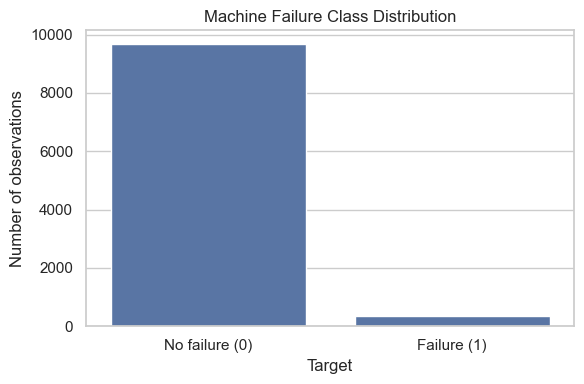

In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Machine failure")
ax.set_title("Machine Failure Class Distribution")
ax.set_xticklabels(["No failure (0)", "Failure (1)"])
ax.set_xlabel("Target")
ax.set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

## 4. Data cleaning and feature selection

The target is `Machine failure`. The following columns are excluded from the predictors:

- `UDI` and `Product ID`: identifiers, not operating sensor measurements.
- `Machine failure`: the target itself.
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF`: failure-mode labels. Including them would leak target-related information.

The primary experiment uses the same five numeric sensor features as your original notebook. `Type` is left out so the PCA and non-PCA comparison remains focused on the same sensor inputs.

We do **not** automatically remove IQR outliers. Extreme sensor readings may be meaningful signals of abnormal machine operation, so removing them could discard useful failure information.

In [6]:
target_col = "Machine failure"

sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

required_columns = sensor_features + [target_col]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

df = df.drop_duplicates().copy()
df = df.dropna(subset=required_columns).copy()

X = df[sensor_features].copy()
y = df[target_col].astype(int).copy()

print("Cleaned X shape:", X.shape)
print("Cleaned y shape:", y.shape)
print("\nTarget counts:")
display(y.value_counts().sort_index().rename(index={0: "No failure", 1: "Failure"}).to_frame("Count"))

Cleaned X shape: (10000, 5)
Cleaned y shape: (10000,)

Target counts:


,Count
Machine failure,
No failure,9661
Failure,339


## 5. Exploratory data analysis (EDA)

In [7]:
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


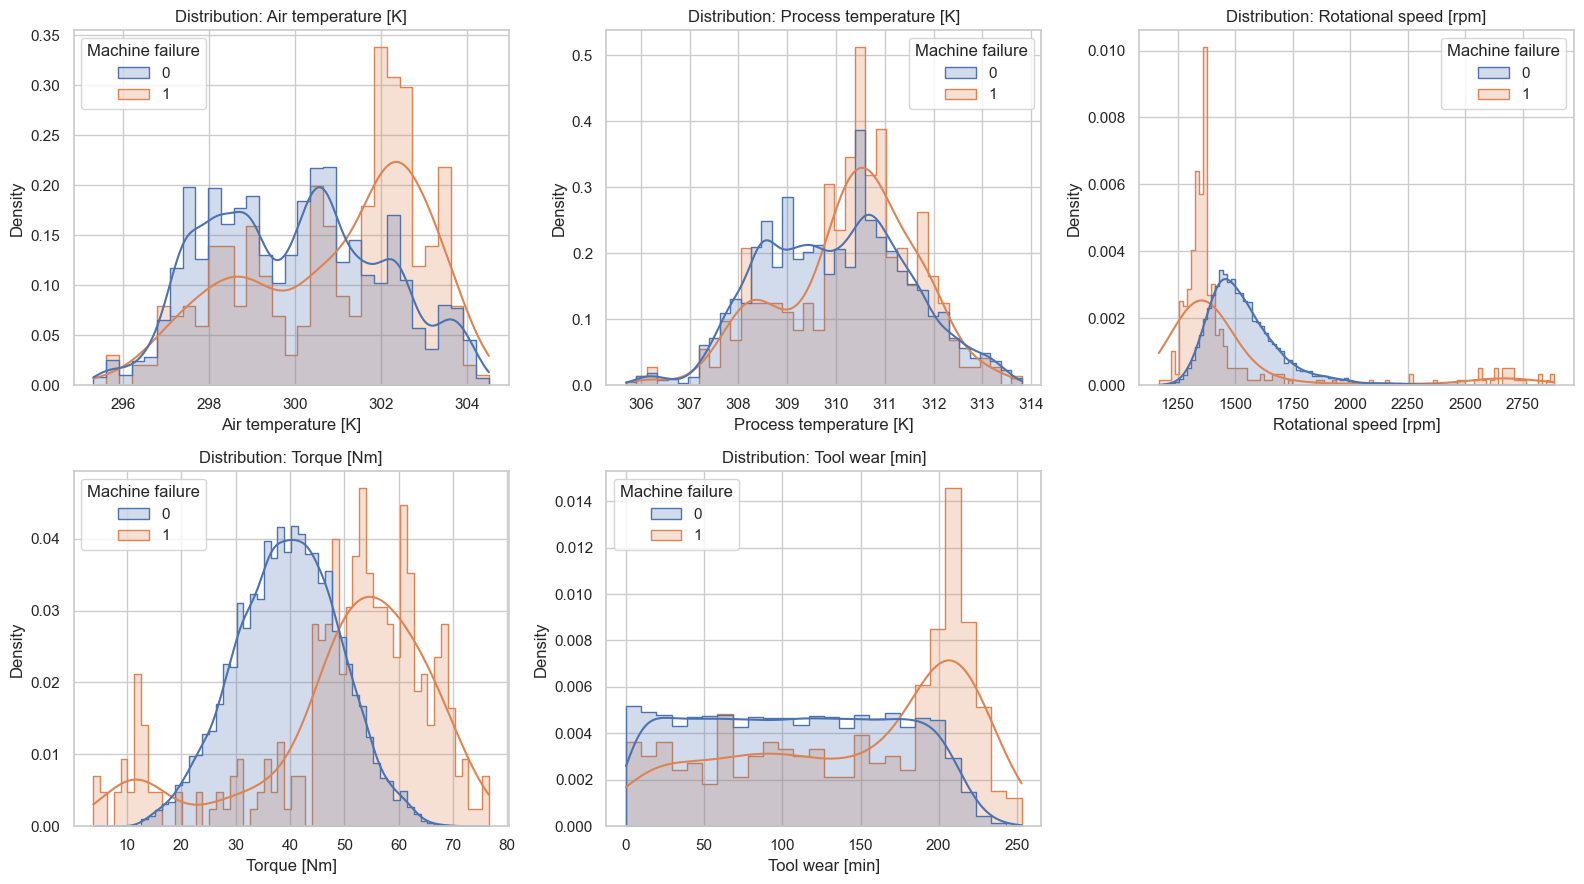

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feature in enumerate(sensor_features):
    sns.histplot(data=df, x=feature, hue=target_col, kde=True,
                 stat="density", common_norm=False, element="step", ax=axes[i])
    axes[i].set_title(f"Distribution: {feature}")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

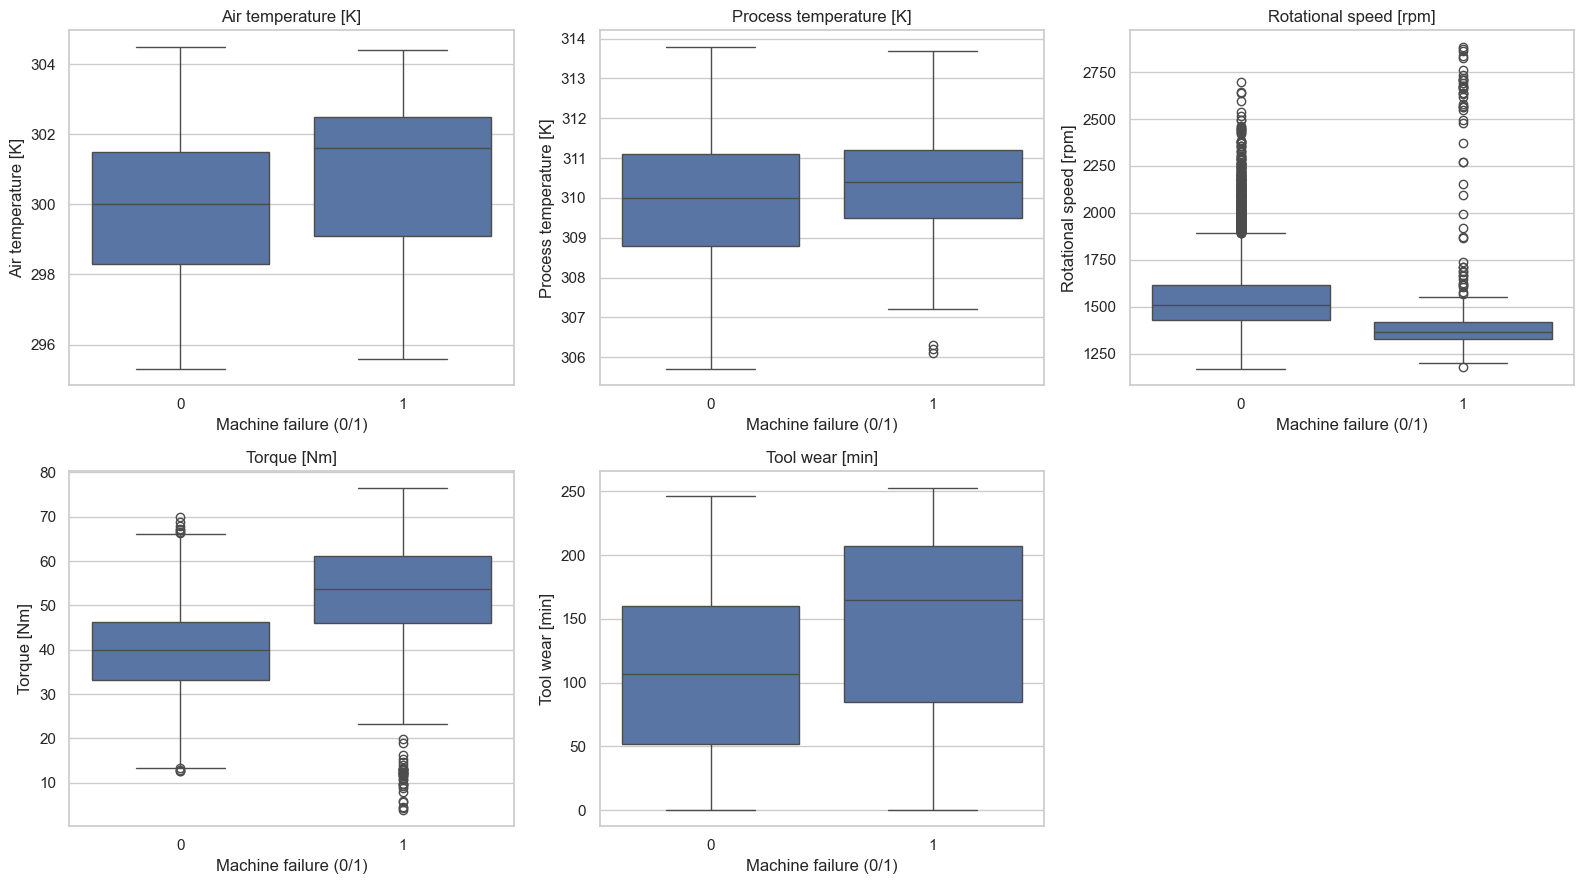

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feature in enumerate(sensor_features):
    sns.boxplot(data=df, x=target_col, y=feature, ax=axes[i])
    axes[i].set_title(feature)
    axes[i].set_xlabel("Machine failure (0/1)")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

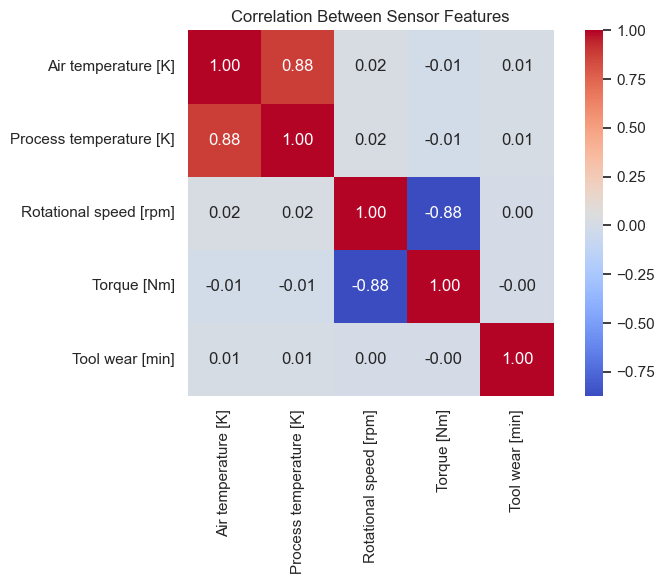

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Between Sensor Features")
plt.tight_layout()
plt.show()

,Failures,Total,Failure rate
Type,,,
H,21,1003,2.09
L,235,6000,3.92
M,83,2997,2.77


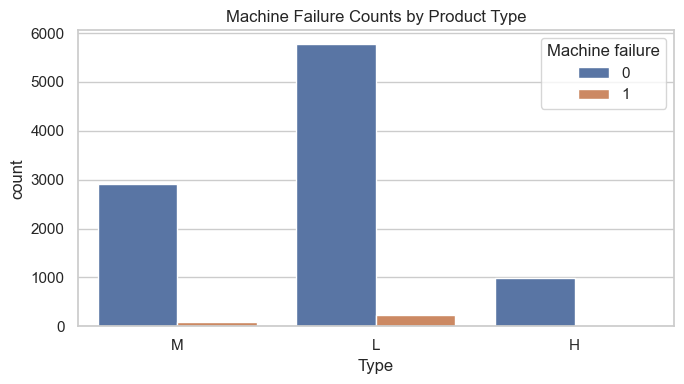

In [11]:
if "Type" in df.columns:
    type_failure_rate = df.groupby("Type")[target_col].agg(["sum", "count", "mean"])
    type_failure_rate = type_failure_rate.rename(
        columns={"sum": "Failures", "count": "Total", "mean": "Failure rate"}
    )
    type_failure_rate["Failure rate"] *= 100
    display(type_failure_rate.round(2))

    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x="Type", hue=target_col)
    plt.title("Machine Failure Counts by Product Type")
    plt.tight_layout()
    plt.show()

## 6. Train-test split (stratified)

**Yes, stratification is recommended here.** Since failures are rare, `stratify=y` preserves approximately the same failure proportion in both training and test sets.

The split is performed on the original, imbalanced data. This must happen **before** SMOTE.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training target distribution:")
display(y_train.value_counts().sort_index().to_frame("Count"))
print("Testing target distribution (kept original):")
display(y_test.value_counts().sort_index().to_frame("Count"))

print("Training failure rate: {:.2f}%".format(y_train.mean() * 100))
print("Testing failure rate:  {:.2f}%".format(y_test.mean() * 100))

Training target distribution:


,Count
Machine failure,
0,7246
1,254


Testing target distribution (kept original):


,Count
Machine failure,
0,2415
1,85


Training failure rate: 3.39%
Testing failure rate:  3.40%


## 7. Upsample the training set using SMOTE

SMOTE creates synthetic minority-class examples by interpolating between minority-class neighbors. It is applied **only to `X_train` and `y_train`**.

The default `sampling_strategy="auto"` increases the minority class to the majority-class count. This creates a balanced training set. The test set remains untouched.

For a stricter experiment, you can later compare SMOTE with `class_weight="balanced"` or tune the sampling ratio using cross-validation.

In [13]:
original_scaler = StandardScaler()
X_train_scaled = original_scaler.fit_transform(X_train)
X_test_scaled = original_scaler.transform(X_test)

smote = SMOTE(random_state=RANDOM_STATE, sampling_strategy="auto")
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:")
display(y_train.value_counts().sort_index().to_frame("Count"))
print("After SMOTE:")
display(pd.Series(y_train_smote).value_counts().sort_index().to_frame("Count"))
print("Test set (must remain original):")
display(y_test.value_counts().sort_index().to_frame("Count"))

Before SMOTE:


,Count
Machine failure,
0,7246
1,254


After SMOTE:


,Count
Machine failure,
0,7246
1,7246


Test set (must remain original):


,Count
Machine failure,
0,2415
1,85


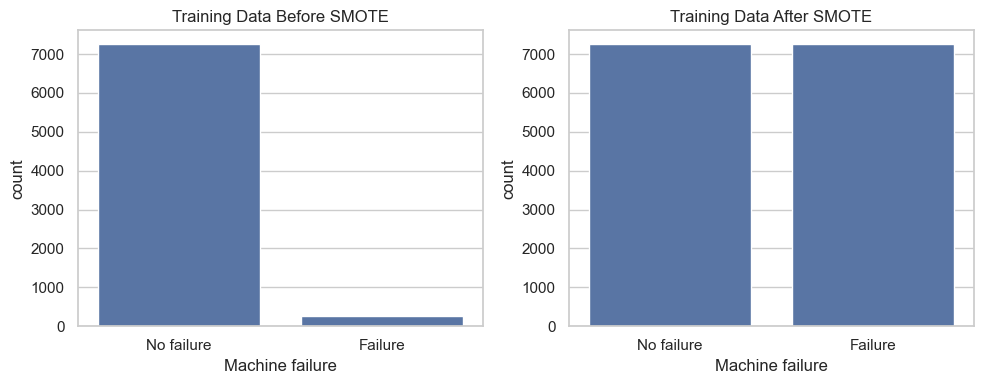

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Training Data Before SMOTE")
axes[0].set_xticklabels(["No failure", "Failure"])
sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("Training Data After SMOTE")
axes[1].set_xticklabels(["No failure", "Failure"])
plt.tight_layout()
plt.show()

## 8. Evaluation helper functions

Accuracy alone is not enough for an imbalanced problem. We report:

- **Precision:** Of the predicted failures, how many were actual failures?
- **Recall:** Of the actual failures, how many did the model detect?
- **F1-score:** Balance between precision and recall.
- **ROC-AUC and PR-AUC:** Ranking performance across thresholds; PR-AUC is especially informative for a rare positive class.
- **Confusion matrix:** TN, FP, FN, TP.

Confusion matrix layout: `[[TN, FP], [FN, TP]]`.

In [15]:
def evaluate_classifier(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (failure)": precision_score(y_eval, pred, zero_division=0),
        "Recall (failure)": recall_score(y_eval, pred, zero_division=0),
        "F1 (failure)": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba)
    }

    print(f"\n{name}")
    print(classification_report(
        y_eval, pred, labels=[0, 1],
        target_names=["No failure", "Failure"],
        zero_division=0
    ))

    cm = confusion_matrix(y_eval, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No failure", "Failure"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

    return results, pred, proba

## 9. Model A — Random Forest using original sensor features (without PCA)

Random Forest is tree-based and does not require standardization for its own splits. However, SMOTE uses nearest-neighbor distances, so we standardize the original features using a scaler fitted on the training set before applying SMOTE. The same scaler transforms the untouched test set. This avoids inconsistent train/test scaling and prevents large-unit features from dominating SMOTE distances.

In [16]:
rf_original = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_pca = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


Random Forest - Original Features
              precision    recall  f1-score   support

  No failure       0.99      0.97      0.98      2415
     Failure       0.52      0.80      0.63        85

    accuracy                           0.97      2500
   macro avg       0.76      0.89      0.81      2500
weighted avg       0.98      0.97      0.97      2500



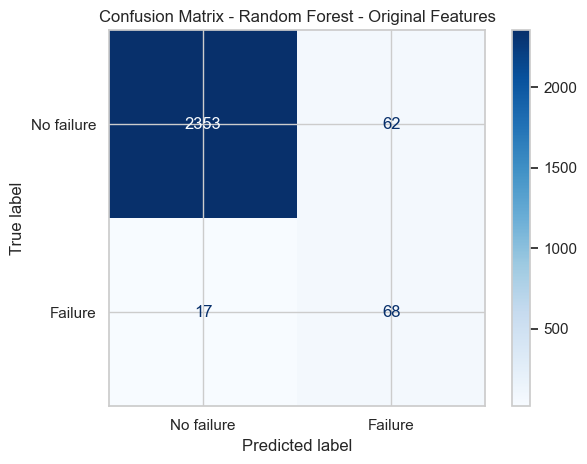

Training accuracy on original (non-SMOTE) training rows: 1.0


In [17]:
rf_original.fit(X_train_smote, y_train_smote)

original_results, y_pred_original, y_prob_original = evaluate_classifier(
    "Random Forest - Original Features",
    rf_original,
    X_test_scaled,
    y_test
)

print("Training accuracy on original (non-SMOTE) training rows:",
      accuracy_score(y_train, rf_original.predict(X_train_scaled)))

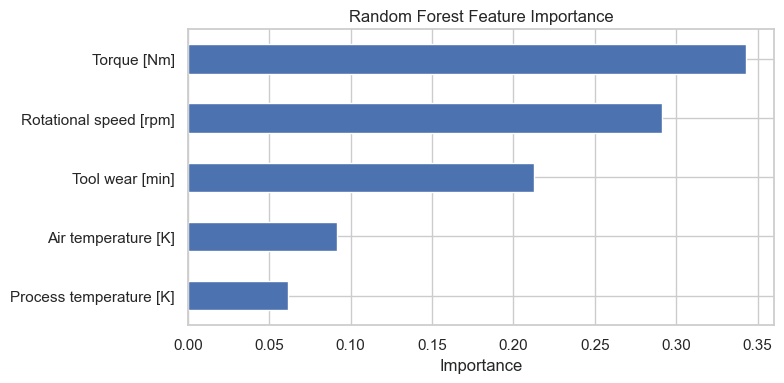

In [18]:
importance = pd.Series(
    rf_original.feature_importances_,
    index=sensor_features
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 4), title="Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 10. Model B — Random Forest using pairwise PCA features

This mirrors the feature construction in your original notebook:

- PCA component 1: Air temperature + Process temperature
- PCA component 1: Rotational speed + Torque
- Original Tool wear feature

**Important correction:** PCA and its scalers are fitted on the training data only. The fitted transformations are then applied to the test data. This prevents information from the test set entering the dimensionality-reduction step.

Each pair is standardized before PCA because the variables have different units and scales. The resulting PCA features are then passed to Random Forest.

In [19]:
temp_scaler = StandardScaler()
speed_torque_scaler = StandardScaler()

temp_train_scaled = temp_scaler.fit_transform(
    X_train[["Air temperature [K]", "Process temperature [K]"]]
)
temp_test_scaled = temp_scaler.transform(
    X_test[["Air temperature [K]", "Process temperature [K]"]]
)

speed_torque_train_scaled = speed_torque_scaler.fit_transform(
    X_train[["Rotational speed [rpm]", "Torque [Nm]"]]
)
speed_torque_test_scaled = speed_torque_scaler.transform(
    X_test[["Rotational speed [rpm]", "Torque [Nm]"]]
)

pca_temp = PCA(n_components=1, random_state=RANDOM_STATE)
pca_speed_torque = PCA(n_components=1, random_state=RANDOM_STATE)

temp_train_pc = pca_temp.fit_transform(temp_train_scaled)
temp_test_pc = pca_temp.transform(temp_test_scaled)

speed_torque_train_pc = pca_speed_torque.fit_transform(speed_torque_train_scaled)
speed_torque_test_pc = pca_speed_torque.transform(speed_torque_test_scaled)

pca_feature_names = [
    "Temperature_PC1",
    "Speed_Torque_PC1",
    "Tool wear [min]"
]

X_train_pca = pd.DataFrame(
    np.column_stack([
        temp_train_pc.ravel(),
        speed_torque_train_pc.ravel(),
        X_train["Tool wear [min]"].to_numpy()
    ]),
    columns=pca_feature_names,
    index=X_train.index
)

X_test_pca = pd.DataFrame(
    np.column_stack([
        temp_test_pc.ravel(),
        speed_torque_test_pc.ravel(),
        X_test["Tool wear [min]"].to_numpy()
    ]),
    columns=pca_feature_names,
    index=X_test.index
)

print("Explained variance ratio — temperature pair:",
      pca_temp.explained_variance_ratio_[0].round(4))
print("Explained variance ratio — speed/torque pair:",
      pca_speed_torque.explained_variance_ratio_[0].round(4))
display(X_train_pca.head())

Explained variance ratio — temperature pair: 0.9386
Explained variance ratio — speed/torque pair: 0.9372


,Temperature_PC1,Speed_Torque_PC1,Tool wear [min]
9350,-1.260955,4.098067,31.0
1125,-2.220117,-1.451768,108.0
2439,-1.085949,1.192496,65.0
5629,1.997952,-1.334295,157.0
2875,-0.114447,2.464139,31.0


In [20]:
pca_representation_scaler = StandardScaler()
X_train_pca_scaled = pca_representation_scaler.fit_transform(X_train_pca)
X_test_pca_scaled = pca_representation_scaler.transform(X_test_pca)

X_train_pca_smote, y_train_pca_smote = smote.fit_resample(
    X_train_pca_scaled, y_train
)

print("PCA training distribution after SMOTE:")
display(pd.Series(y_train_pca_smote).value_counts().sort_index().to_frame("Count"))
print("PCA test distribution (untouched):")
display(y_test.value_counts().sort_index().to_frame("Count"))

PCA training distribution after SMOTE:


,Count
Machine failure,
0,7246
1,7246


PCA test distribution (untouched):


,Count
Machine failure,
0,2415
1,85



Random Forest - Pairwise PCA Features
              precision    recall  f1-score   support

  No failure       0.99      0.93      0.96      2415
     Failure       0.28      0.71      0.40        85

    accuracy                           0.93      2500
   macro avg       0.63      0.82      0.68      2500
weighted avg       0.96      0.93      0.94      2500



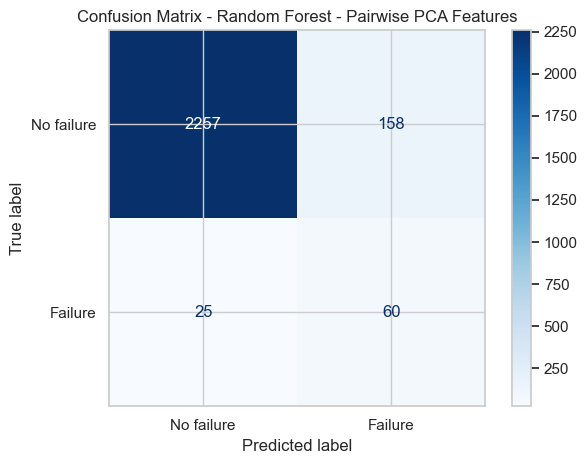

Training accuracy on original (non-SMOTE) PCA training rows: 1.0


In [21]:
rf_pca.fit(X_train_pca_smote, y_train_pca_smote)

pca_results, y_pred_pca, y_prob_pca = evaluate_classifier(
    "Random Forest - Pairwise PCA Features",
    rf_pca,
    X_test_pca_scaled,
    y_test
)

print("Training accuracy on original (non-SMOTE) PCA training rows:",
      accuracy_score(y_train, rf_pca.predict(X_train_pca_scaled)))

## 11. Compare PCA and non-PCA models

Both models use:
- The same original stratified train-test split
- The same target
- SMOTE applied only to their respective training representations
- The same untouched test observations

This makes the comparison fair. A lower PCA score can indicate that compressing each feature pair into one component removed information useful for separating failure from non-failure. PCA preserves variance, not necessarily target-discriminative information.

In [22]:
comparison = pd.DataFrame([original_results, pca_results]).set_index("Model")
display(comparison.round(4))

,Accuracy,Precision (failure),Recall (failure),F1 (failure),ROC-AUC,PR-AUC
Model,,,,,,
Random Forest - Original Features,0.9684,0.5231,0.8000,0.6326,0.9795,0.7103
Random Forest - Pairwise PCA Features,0.9268,0.2752,0.7059,0.3960,0.9472,0.4052


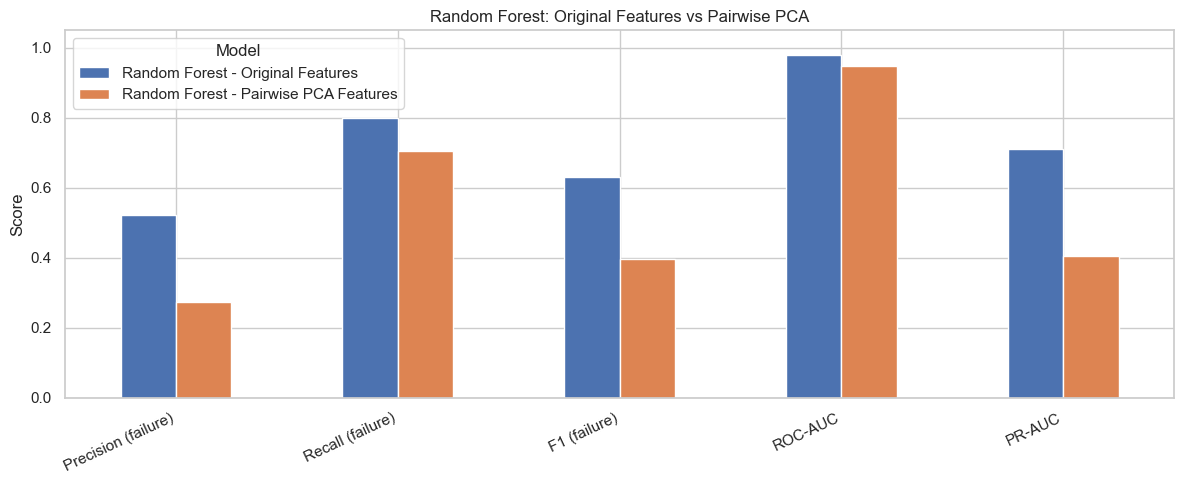

In [23]:
metrics_to_plot = ["Precision (failure)", "Recall (failure)", "F1 (failure)", "ROC-AUC", "PR-AUC"]
comparison[metrics_to_plot].T.plot(kind="bar", figsize=(12, 5))
plt.title("Random Forest: Original Features vs Pairwise PCA")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

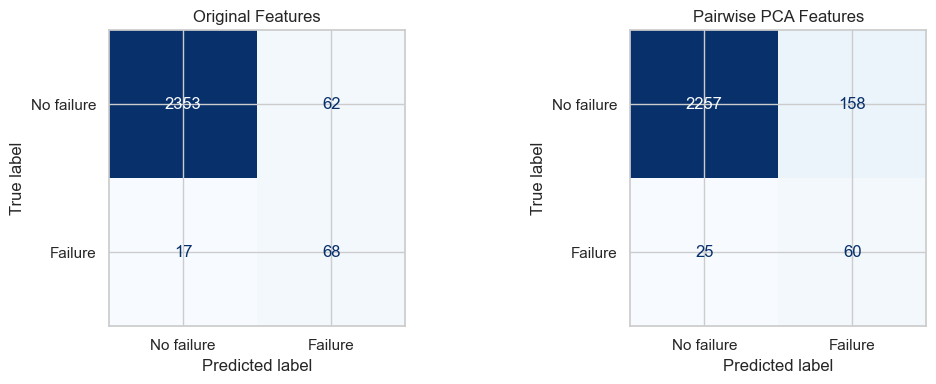

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_original, labels=[0, 1]),
    display_labels=["No failure", "Failure"]
).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Original Features")

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_pca, labels=[0, 1]),
    display_labels=["No failure", "Failure"]
).plot(ax=axes[1], cmap="Blues", values_format="d", colorbar=False)
axes[1].set_title("Pairwise PCA Features")

plt.tight_layout()
plt.show()

In [25]:
def print_confusion_details(title, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(title)
    print(f"True negatives  (correctly predicted no failure): {tn}")
    print(f"False positives (false alarms):                 {fp}")
    print(f"False negatives (missed failures):              {fn}")
    print(f"True positives  (detected failures):            {tp}")
    print()

print_confusion_details("Original-feature model", y_test, y_pred_original)
print_confusion_details("PCA-feature model", y_test, y_pred_pca)

Original-feature model
True negatives  (correctly predicted no failure): 2353
False positives (false alarms):                 62
False negatives (missed failures):              17
True positives  (detected failures):            68

PCA-feature model
True negatives  (correctly predicted no failure): 2257
False positives (false alarms):                 158
False negatives (missed failures):              25
True positives  (detected failures):            60



### How to interpret the confusion matrices

- **High FN:** The model misses real machine failures. This is particularly important to reduce in predictive maintenance.
- **High FP:** The model raises unnecessary maintenance alerts.
- **High TP:** The model correctly detects failures.
- **High TN:** The model correctly recognizes normal operation.

Do not select a model using accuracy alone. Prefer a model with useful failure recall and an acceptable false-alarm rate. Use the printed metrics and confusion matrices from your actual run to make the final choice.

## 12. Anomaly detection — Isolation Forest

Random Forest is supervised: it learns from the known `Machine failure` labels. Isolation Forest is unsupervised: it learns patterns in sensor observations and flags unusual points.

For a fair test:
- Fit Isolation Forest using **normal observations from the training set only**.
- Do not use the test labels during fitting.
- Evaluate anomaly flags against test failure labels as a proxy.

An anomaly is not automatically a machine failure. A rare but valid operating condition may be flagged, and a real failure may not look statistically unusual.

Anomalies flagged in test set: 634
                 precision    recall  f1-score   support

     No failure       0.99      0.77      0.87      2415
Failure (proxy)       0.11      0.84      0.20        85

       accuracy                           0.77      2500
      macro avg       0.55      0.80      0.53      2500
   weighted avg       0.96      0.77      0.84      2500



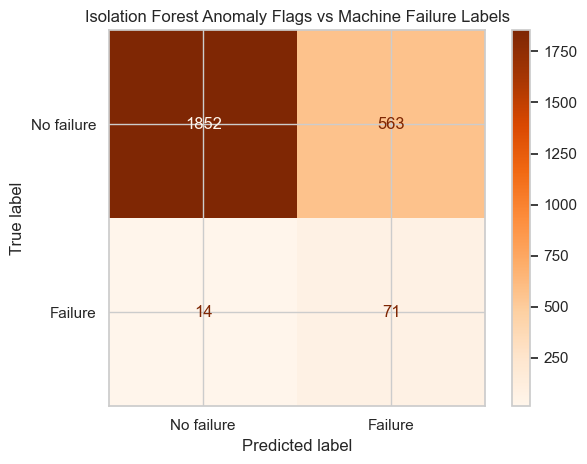

In [26]:
iso_scaler = StandardScaler()

X_train_normal = X_train.loc[y_train == 0]
X_test_scaled_for_iso = iso_scaler.fit(X_train_normal).transform(X_test)
X_train_normal_scaled = iso_scaler.transform(X_train_normal)

iso_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

iso_forest.fit(X_train_normal_scaled)

iso_test_labels = iso_forest.predict(X_test_scaled_for_iso)
y_pred_anomaly = (iso_test_labels == -1).astype(int)

print("Anomalies flagged in test set:", int(y_pred_anomaly.sum()))
print(classification_report(
    y_test, y_pred_anomaly,
    labels=[0, 1],
    target_names=["No failure", "Failure (proxy)"],
    zero_division=0
))

cm_iso = confusion_matrix(y_test, y_pred_anomaly, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm_iso,
    display_labels=["No failure", "Failure"]
).plot(cmap="Oranges", values_format="d")
plt.title("Isolation Forest Anomaly Flags vs Machine Failure Labels")
plt.tight_layout()
plt.show()

## 13. Combined condition assessment

Use the original-feature Random Forest as the primary predictor of known failures. Use Isolation Forest as a separate anomaly warning.

The three-state interpretation is:

1. **Predicted failure:** Random Forest predicts class 1.
2. **Unusual condition — inspect:** Random Forest predicts class 0, but Isolation Forest flags an anomaly.
3. **No alert:** Neither model raises an alert.

For a simple binary comparison, the combined alert below is `RF failure OR Isolation Forest anomaly`. This can increase recall but may also increase false positives. The three-state output preserves the distinction between a predicted known failure and an unusual observation.

In [27]:
rf_primary_prediction = y_pred_original
combined_binary_alert = ((rf_primary_prediction == 1) | (y_pred_anomaly == 1)).astype(int)

condition_status = np.select(
    [
        rf_primary_prediction == 1,
        (rf_primary_prediction == 0) & (y_pred_anomaly == 1)
    ],
    [
        "Predicted failure",
        "Unusual condition - inspect"
    ],
    default="No alert"
)

condition_assessment = pd.DataFrame({
    "Actual machine failure": y_test.to_numpy(),
    "Random Forest prediction": rf_primary_prediction,
    "Isolation Forest anomaly": y_pred_anomaly,
    "Condition assessment": condition_status
}, index=y_test.index)

display(condition_assessment.head(15))
display(condition_assessment["Condition assessment"].value_counts().to_frame("Observations"))

,Actual machine failure,Random Forest prediction,Isolation Forest anomaly,Condition assessment
1390,0,0,0,No alert
2925,0,0,0,No alert
2488,0,0,0,No alert
5844,0,0,0,No alert
7978,0,0,0,No alert
4161,0,0,0,No alert
3132,0,0,0,No alert
1092,0,0,1,Unusual condition - inspect
67,0,0,0,No alert
5,0,0,0,No alert


,Observations
Condition assessment,
No alert,1835
Unusual condition - inspect,535
Predicted failure,130


Combined binary alert = RF positive OR Isolation Forest anomaly
              precision    recall  f1-score   support

  No failure       1.00      0.76      0.86      2415
     Failure       0.12      0.96      0.22        85

    accuracy                           0.77      2500
   macro avg       0.56      0.86      0.54      2500
weighted avg       0.97      0.77      0.84      2500



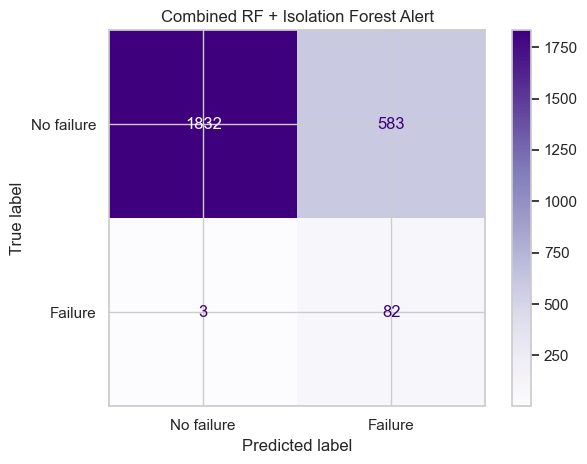

In [28]:
combined_cm = confusion_matrix(y_test, combined_binary_alert, labels=[0, 1])
print("Combined binary alert = RF positive OR Isolation Forest anomaly")
print(classification_report(
    y_test, combined_binary_alert,
    labels=[0, 1],
    target_names=["No failure", "Failure"],
    zero_division=0
))
ConfusionMatrixDisplay(
    confusion_matrix=combined_cm,
    display_labels=["No failure", "Failure"]
).plot(cmap="Purples", values_format="d")
plt.title("Combined RF + Isolation Forest Alert")
plt.tight_layout()
plt.show()

## 14. Phase 1 baseline results and conclusions

Run this cell after all previous cells. It identifies the stronger Random Forest representation using **failure-class F1-score** and prints the key metrics.

The best representation is determined from your actual run, not assumed in advance. If the original-feature model wins, a reasonable interpretation is that the original sensor values preserve useful feature-specific thresholds that are weakened when PCA compresses each pair into a single component.

### Limitations to mention in the report

- AI4I 2020 is a synthetic predictive-maintenance dataset; results do not automatically generalize to real factories.
- `Machine failure` is a binary label, while Isolation Forest identifies statistical outliers. These are related but not equivalent concepts.
- The dataset does not provide a true per-machine time series for remaining-useful-life estimation.
- The combined OR alert may increase recall at the cost of additional false alarms.

These baseline experiments and their saved outputs are preserved as the reference point for Phase 2.

In [29]:
best_model_name = comparison["F1 (failure)"].idxmax()
print("Better Random Forest representation by failure F1-score:", best_model_name)
print("\nMetric comparison:")
display(comparison.round(4))

print("\nRecommended interpretation:")
if best_model_name == "Random Forest - Original Features":
    print(
        "The original sensor features performed better in this experiment. "
        "This is consistent with PCA removing or mixing information that is useful "
        "for separating failure and non-failure observations."
    )
else:
    print(
        "The pairwise PCA representation performed better in this experiment. "
        "The compressed components may have retained useful joint variation for this split."
    )

print(
    "\nUse the confusion matrix, especially failure false negatives and false positives, "
    "alongside F1, recall and PR-AUC before selecting the final model."
)

Better Random Forest representation by failure F1-score: Random Forest - Original Features

Metric comparison:


,Accuracy,Precision (failure),Recall (failure),F1 (failure),ROC-AUC,PR-AUC
Model,,,,,,
Random Forest - Original Features,0.9684,0.5231,0.8000,0.6326,0.9795,0.7103
Random Forest - Pairwise PCA Features,0.9268,0.2752,0.7059,0.3960,0.9472,0.4052



Recommended interpretation:
The original sensor features performed better in this experiment. This is consistent with PCA removing or mixing information that is useful for separating failure and non-failure observations.

Use the confusion matrix, especially failure false negatives and false positives, alongside F1, recall and PR-AUC before selecting the final model.


## 15. Phase 2 — leakage-safe model optimization

The Phase 1 holdout results above are preserved unchanged as the baseline. Every experiment below uses the existing training partition (`X_train`, `y_train`) for cross-validation, hyperparameter search, and threshold choice. The held-out `X_test`, `y_test` are used only after these choices are fixed.

We use five-fold stratified cross-validation with an imbalanced-learn pipeline. Scaling and SMOTE are fit inside each fold. Random Forest comparisons include SMOTE, class weighting, and no resampling. Logistic Regression and HistGradientBoosting are included as distinct linear and boosting approaches. The hyperparameter search optimizes average precision (PR-AUC), not accuracy.

In [30]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    make_scorer, roc_curve, precision_recall_curve,
    auc
)
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
)
from scipy.stats import randint

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def false_positive_rate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fp / (fp + tn) if (fp + tn) else 0.0

def false_negative_rate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fn / (fn + tp) if (fn + tp) else 0.0

SCORING = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'fpr': make_scorer(false_positive_rate),
    'fnr': make_scorer(false_negative_rate),
}

def make_rf_pipeline(sampler='passthrough', class_weight=None, n_estimators=200):
    return ImbPipeline(steps=[
        ('scale', StandardScaler()),
        ('sampler', clone(sampler) if sampler != 'passthrough' else 'passthrough'),
        ('model', RandomForestClassifier(
            n_estimators=n_estimators, random_state=RANDOM_STATE, n_jobs=-1,
            class_weight=class_weight
        ))
    ])

print('Training rows used for all Phase 2 selection:', len(X_train))
print('Final holdout rows reserved for final evaluation:', len(X_test))
print('CV folds:', CV.n_splits)

X_rf_dev, X_threshold_val, y_rf_dev, y_threshold_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)
print("RF search rows:", len(X_rf_dev), "| Threshold calibration rows:", len(X_threshold_val))

Training rows used for all Phase 2 selection: 7500
Final holdout rows reserved for final evaluation: 2500
CV folds: 5
RF search rows: 6000 | Threshold calibration rows: 1500


### 15.1 Stratified cross-validation comparisons

All reported values are mean ± standard deviation across five validation folds from the original training partition. FPR and FNR use the model's default 0.5 classification threshold for these comparisons. Random Forest scaling has no material effect on tree splits; it is inside the pipeline so SMOTE neighbor distances are standardized and every fold learns its own scaling parameters.

In [31]:
rf_cv_pipelines = {
    'Random Forest + SMOTE': make_rf_pipeline(
        sampler=SMOTE(random_state=RANDOM_STATE), n_estimators=200
    ),
    'Random Forest + class_weight=balanced': make_rf_pipeline(
        sampler='passthrough', class_weight='balanced', n_estimators=200
    ),
    'Random Forest, no resampling': make_rf_pipeline(
        sampler='passthrough', class_weight=None, n_estimators=200
    ),
}

cv_records = []
cv_estimators = {}
for model_name, estimator in rf_cv_pipelines.items():
    print('Cross-validating:', model_name)
    fold_scores = cross_validate(
        estimator, X_train, y_train, cv=CV, scoring=SCORING,
        n_jobs=1, return_train_score=False
    )
    cv_estimators[model_name] = estimator
    record = {'Model': model_name}
    for metric in SCORING:
        vals = fold_scores[f'test_{metric}']
        record[f'{metric.upper()} mean'] = vals.mean()
        record[f'{metric.upper()} std'] = vals.std(ddof=1)
    cv_records.append(record)

cv_rf_summary = pd.DataFrame(cv_records).set_index('Model')
display(cv_rf_summary.round(4))

Cross-validating: Random Forest + SMOTE


Cross-validating: Random Forest + class_weight=balanced


Cross-validating: Random Forest, no resampling


,ACCURACY mean,ACCURACY std,PRECISION mean,PRECISION std,RECALL mean,RECALL std,F1 mean,F1 std,ROC_AUC mean,ROC_AUC std,PR_AUC mean,PR_AUC std,FPR mean,FPR std,FNR mean,FNR std
Model,,,,,,,,,,,,,,,,
Random Forest + SMOTE,0.9657,0.0040,0.4988,0.0434,0.7594,0.0936,0.5994,0.0420,0.9695,0.0140,0.7031,0.0713,0.0270,0.0054,0.2406,0.0936
Random Forest + class_weight=balanced,0.9795,0.0028,0.8800,0.0948,0.4604,0.0788,0.6003,0.0691,0.9651,0.0166,0.7450,0.0840,0.0023,0.0018,0.5396,0.0788
"Random Forest, no resampling",0.9811,0.0023,0.8311,0.0486,0.5550,0.0725,0.6631,0.0540,0.9656,0.0159,0.7727,0.0491,0.0040,0.0013,0.4450,0.0725


### 15.2 Additional models

Logistic Regression uses standardized sensor values and training-fold SMOTE. HistGradientBoosting uses the same fold-local scaling and SMOTE, while its tree splits do not themselves require scaling. These are evaluated with the same five folds and metrics so they provide meaningful comparisons rather than extra model names.

In [32]:
additional_pipelines = {
    'Logistic Regression + SMOTE': ImbPipeline(steps=[
        ('scale', StandardScaler()),
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('model', LogisticRegression(
            max_iter=2000, random_state=RANDOM_STATE, solver='liblinear'
        ))
    ]),
    'HistGradientBoosting + SMOTE': ImbPipeline(steps=[
        ('scale', StandardScaler()),
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('model', HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.1, random_state=RANDOM_STATE
        ))
    ])
}

additional_cv_records = []
for model_name, estimator in additional_pipelines.items():
    print('Cross-validating:', model_name)
    fold_scores = cross_validate(
        estimator, X_train, y_train, cv=CV, scoring=SCORING,
        n_jobs=1, return_train_score=False
    )
    record = {'Model': model_name}
    for metric in SCORING:
        vals = fold_scores[f'test_{metric}']
        record[f'{metric.upper()} mean'] = vals.mean()
        record[f'{metric.upper()} std'] = vals.std(ddof=1)
    additional_cv_records.append(record)

additional_cv_summary = pd.DataFrame(additional_cv_records).set_index('Model')
cv_summary = pd.concat([cv_rf_summary, additional_cv_summary])
display(additional_cv_summary.round(4))
print('All cross-validation models:')
display(cv_summary.round(4))

Cross-validating: Logistic Regression + SMOTE
Cross-validating: HistGradientBoosting + SMOTE


,ACCURACY mean,ACCURACY std,PRECISION mean,PRECISION std,RECALL mean,RECALL std,F1 mean,F1 std,ROC_AUC mean,ROC_AUC std,PR_AUC mean,PR_AUC std,FPR mean,FPR std,FNR mean,FNR std
Model,,,,,,,,,,,,,,,,
Logistic Regression + SMOTE,0.8335,0.0070,0.1480,0.0109,0.8227,0.0509,0.2509,0.0178,0.9040,0.0189,0.4312,0.0398,0.1662,0.0065,0.1773,0.0509
HistGradientBoosting + SMOTE,0.9700,0.0049,0.5415,0.0551,0.7830,0.0798,0.6388,0.0548,0.9697,0.0142,0.7713,0.0694,0.0235,0.0046,0.2170,0.0798


All cross-validation models:


,ACCURACY mean,ACCURACY std,PRECISION mean,PRECISION std,RECALL mean,RECALL std,F1 mean,F1 std,ROC_AUC mean,ROC_AUC std,PR_AUC mean,PR_AUC std,FPR mean,FPR std,FNR mean,FNR std
Model,,,,,,,,,,,,,,,,
Random Forest + SMOTE,0.9657,0.0040,0.4988,0.0434,0.7594,0.0936,0.5994,0.0420,0.9695,0.0140,0.7031,0.0713,0.0270,0.0054,0.2406,0.0936
Random Forest + class_weight=balanced,0.9795,0.0028,0.8800,0.0948,0.4604,0.0788,0.6003,0.0691,0.9651,0.0166,0.7450,0.0840,0.0023,0.0018,0.5396,0.0788
"Random Forest, no resampling",0.9811,0.0023,0.8311,0.0486,0.5550,0.0725,0.6631,0.0540,0.9656,0.0159,0.7727,0.0491,0.0040,0.0013,0.4450,0.0725
Logistic Regression + SMOTE,0.8335,0.0070,0.1480,0.0109,0.8227,0.0509,0.2509,0.0178,0.9040,0.0189,0.4312,0.0398,0.1662,0.0065,0.1773,0.0509
HistGradientBoosting + SMOTE,0.9700,0.0049,0.5415,0.0551,0.7830,0.0798,0.6388,0.0548,0.9697,0.0142,0.7713,0.0694,0.0235,0.0046,0.2170,0.0798


### 15.3 Randomized Random Forest search

RandomizedSearchCV uses five-fold stratified CV on the development slice of the training partition and refits the best configuration using average precision. Its pipeline fits scaling and SMOTE independently inside each fold. The sampled search space covers all requested forest parameters. The holdout test set is not passed to the search.

In [33]:
rf_search_pipeline = make_rf_pipeline(
    sampler=SMOTE(random_state=RANDOM_STATE), n_estimators=300
)
rf_parameter_distributions = {
    'model__n_estimators': [150, 250, 350, 500],
    'model__max_depth': [None, 8, 12, 18, 25],
    'model__min_samples_split': randint(2, 16),
    'model__min_samples_leaf': randint(1, 9),
    'model__max_features': ['sqrt', 0.5, 0.75, 1.0],
    'model__class_weight': [None, 'balanced', 'balanced_subsample']
}

rf_search = RandomizedSearchCV(
    estimator=rf_search_pipeline,
    param_distributions=rf_parameter_distributions,
    n_iter=16, scoring='average_precision', refit=True,
    cv=CV, random_state=RANDOM_STATE, n_jobs=1,
    return_train_score=False, verbose=1
)
rf_search.fit(X_rf_dev, y_rf_dev)
best_rf = rf_search.best_estimator_
print('Best CV average precision:', round(rf_search.best_score_, 4))
print('Best parameters:')
display(pd.Series(rf_search.best_params_, name='Value').to_frame())
print('Best-score fold standard deviation:',
      round(rf_search.cv_results_['std_test_score'][rf_search.best_index_], 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits


Best CV average precision: 0.6929
Best parameters:


,Value
model__class_weight,balanced_subsample
model__max_depth,18
model__max_features,sqrt
model__min_samples_leaf,7
model__min_samples_split,12
model__n_estimators,500


Best-score fold standard deviation: 0.0763


### 15.4 Select the operating threshold using a training-only calibration split

The threshold is selected using a stratified calibration slice held out from the RandomizedSearchCV development rows. The criterion is: **maximize failure F1 subject to false-positive rate ≤ 5%**, with recall as a tie-breaker. This puts an explicit cap on unnecessary maintenance alerts while balancing precision and missed failures. The calibration slice is not used to fit or tune the candidate forest, and final test labels are not used. PR-AUC is a ranking metric and therefore remains constant across classification thresholds; the table includes it to make that distinction visible.

In [34]:
calibration_probability = best_rf.predict_proba(X_threshold_val)[:, 1]
calibration_pr_auc = average_precision_score(y_threshold_val, calibration_probability)
threshold_grid = np.round(np.arange(0.00, 1.011, 0.01), 2)
threshold_rows = []
for threshold in threshold_grid:
    calibration_pred = (calibration_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_threshold_val, calibration_pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_threshold_val, calibration_pred, zero_division=0),
        'Recall': recall_score(y_threshold_val, calibration_pred, zero_division=0),
        'F1': f1_score(y_threshold_val, calibration_pred, zero_division=0),
        'FPR': fp / (fp + tn) if fp + tn else 0.0,
        'FNR': fn / (fn + tp) if fn + tp else 0.0,
        'PR-AUC': calibration_pr_auc
    })
threshold_results = pd.DataFrame(threshold_rows)
feasible_thresholds = threshold_results[threshold_results['FPR'] <= 0.05]
if feasible_thresholds.empty:
    raise RuntimeError('No candidate threshold meets the specified 5% FPR cap.')
selected_threshold_row = feasible_thresholds.sort_values(
    ['F1', 'Recall', 'Precision'], ascending=False
).iloc[0]
selected_threshold = float(selected_threshold_row['Threshold'])
print('Selected threshold:', selected_threshold)
print('Selection criterion: maximum calibration F1 among thresholds with calibration FPR <= 5%')
display(threshold_results[threshold_results['Threshold'].isin([0.10, 0.20, 0.30, 0.40, 0.50, selected_threshold])].round(4))
print('Selected calibration operating point:')
display(selected_threshold_row.to_frame('Value').round(4))

Selected threshold: 0.78
Selection criterion: maximum calibration F1 among thresholds with calibration FPR <= 5%


,Threshold,Precision,Recall,F1,FPR,FNR,PR-AUC
10,0.10,0.1976,0.9804,0.3289,0.1401,0.0196,0.6952
20,0.20,0.2593,0.9608,0.4083,0.0966,0.0392,0.6952
30,0.30,0.3267,0.9608,0.4876,0.0697,0.0392,0.6952
40,0.40,0.3889,0.9608,0.5537,0.0531,0.0392,0.6952
50,0.50,0.4340,0.9020,0.5860,0.0414,0.0980,0.6952
78,0.78,0.6735,0.6471,0.6600,0.0110,0.3529,0.6952


Selected calibration operating point:


,Value
Threshold,0.7800
Precision,0.6735
Recall,0.6471
F1,0.6600
FPR,0.0110
FNR,0.3529
PR-AUC,0.6952


### 15.5 Final holdout comparison

Only now are the new candidate models refit on all training rows and evaluated on the untouched holdout. The tuned Random Forest is reported at both the default 0.5 threshold and the training-selected threshold. Existing Phase 1 original-feature and PCA results remain in the earlier section and are repeated here only to make the holdout comparison easy to read.

In [35]:
final_tuned_rf = clone(best_rf).fit(X_train, y_train)

final_models = {
    'Random Forest + SMOTE (CV baseline)': make_rf_pipeline(
        sampler=SMOTE(random_state=RANDOM_STATE), n_estimators=200
    ),
    'Random Forest + class_weight (CV baseline)': make_rf_pipeline(
        sampler='passthrough', class_weight='balanced', n_estimators=200
    ),
    'Random Forest, no resampling (CV baseline)': make_rf_pipeline(
        sampler='passthrough', class_weight=None, n_estimators=200
    ),
    'Logistic Regression + SMOTE': clone(additional_pipelines['Logistic Regression + SMOTE']),
    'HistGradientBoosting + SMOTE': clone(additional_pipelines['HistGradientBoosting + SMOTE']),
}
for model_name, estimator in final_models.items():
    print('Fitting:', model_name)
    estimator.fit(X_train, y_train)

tuned_rf_probability = final_tuned_rf.predict_proba(X_test)[:, 1]
tuned_rf_pred_05 = (tuned_rf_probability >= 0.5).astype(int)
tuned_rf_pred_selected = (tuned_rf_probability >= selected_threshold).astype(int)

def holdout_metrics(y_true, y_pred, probability=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    result = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Failure precision': precision_score(y_true, y_pred, zero_division=0),
        'Failure recall': recall_score(y_true, y_pred, zero_division=0),
        'Failure F1': f1_score(y_true, y_pred, zero_division=0),
        'FPR': fp / (fp + tn) if fp + tn else 0.0,
        'FNR': fn / (fn + tp) if fn + tp else 0.0,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }
    if probability is not None:
        result['ROC-AUC'] = roc_auc_score(y_true, probability)
        result['PR-AUC'] = average_precision_score(y_true, probability)
    return result

phase2_holdout_predictions = {
    'Random Forest — Phase 1 original features': (y_pred_original, y_prob_original),
    'Random Forest — Phase 1 PCA': (y_pred_pca, y_prob_pca),
}
for model_name, estimator in final_models.items():
    probs = estimator.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.5).astype(int)
    phase2_holdout_predictions[model_name] = (preds, probs)
phase2_holdout_predictions['Tuned RF — threshold 0.50'] = (tuned_rf_pred_05, tuned_rf_probability)
phase2_holdout_predictions[f'Tuned RF — threshold {selected_threshold:.2f}'] = (tuned_rf_pred_selected, tuned_rf_probability)

holdout_records = []
for model_name, (preds, probs) in phase2_holdout_predictions.items():
    metrics = holdout_metrics(y_test, preds, probs)
    metrics['Model'] = model_name
    holdout_records.append(metrics)
phase2_holdout_summary = pd.DataFrame(holdout_records).set_index('Model')
display(phase2_holdout_summary.round(4))

Fitting: Random Forest + SMOTE (CV baseline)


Fitting: Random Forest + class_weight (CV baseline)


Fitting: Random Forest, no resampling (CV baseline)


Fitting: Logistic Regression + SMOTE
Fitting: HistGradientBoosting + SMOTE


,Accuracy,Failure precision,Failure recall,Failure F1,FPR,FNR,TN,FP,FN,TP,ROC-AUC,PR-AUC
Model,,,,,,,,,,,,
Random Forest — Phase 1 original features,0.9684,0.5231,0.8000,0.6326,0.0257,0.2000,2353,62,17,68,0.9795,0.7103
Random Forest — Phase 1 PCA,0.9268,0.2752,0.7059,0.3960,0.0654,0.2941,2257,158,25,60,0.9472,0.4052
Random Forest + SMOTE (CV baseline),0.9684,0.5231,0.8000,0.6326,0.0257,0.2000,2353,62,17,68,0.9785,0.7051
Random Forest + class_weight (CV baseline),0.9820,0.8571,0.5647,0.6809,0.0033,0.4353,2407,8,37,48,0.9726,0.7681
"Random Forest, no resampling (CV baseline)",0.9856,0.8769,0.6706,0.7600,0.0033,0.3294,2407,8,28,57,0.9686,0.7951
Logistic Regression + SMOTE,0.8268,0.1405,0.8000,0.2390,0.1723,0.2000,1999,416,17,68,0.8831,0.3981
HistGradientBoosting + SMOTE,0.9732,0.5726,0.8353,0.6794,0.0219,0.1647,2362,53,14,71,0.9763,0.8039
Tuned RF — threshold 0.50,0.9556,0.4253,0.8706,0.5714,0.0414,0.1294,2315,100,11,74,0.9803,0.7313
Tuned RF — threshold 0.78,0.9772,0.6628,0.6706,0.6667,0.0120,0.3294,2386,29,28,57,0.9803,0.7313


### 15.6 Classification reports, curves, and model comparison

The curves use holdout probabilities only for final visualization after training and threshold selection are complete. The chosen threshold remains the one selected from the reserved training-only calibration split.


Random Forest + SMOTE (CV baseline)
              precision    recall  f1-score   support

  No failure       0.99      0.97      0.98      2415
     Failure       0.52      0.80      0.63        85

    accuracy                           0.97      2500
   macro avg       0.76      0.89      0.81      2500
weighted avg       0.98      0.97      0.97      2500


Random Forest + class_weight (CV baseline)
              precision    recall  f1-score   support

  No failure       0.98      1.00      0.99      2415
     Failure       0.86      0.56      0.68        85

    accuracy                           0.98      2500
   macro avg       0.92      0.78      0.84      2500
weighted avg       0.98      0.98      0.98      2500


Random Forest, no resampling (CV baseline)
              precision    recall  f1-score   support

  No failure       0.99      1.00      0.99      2415
     Failure       0.88      0.67      0.76        85

    accuracy                           0.99      2500
   

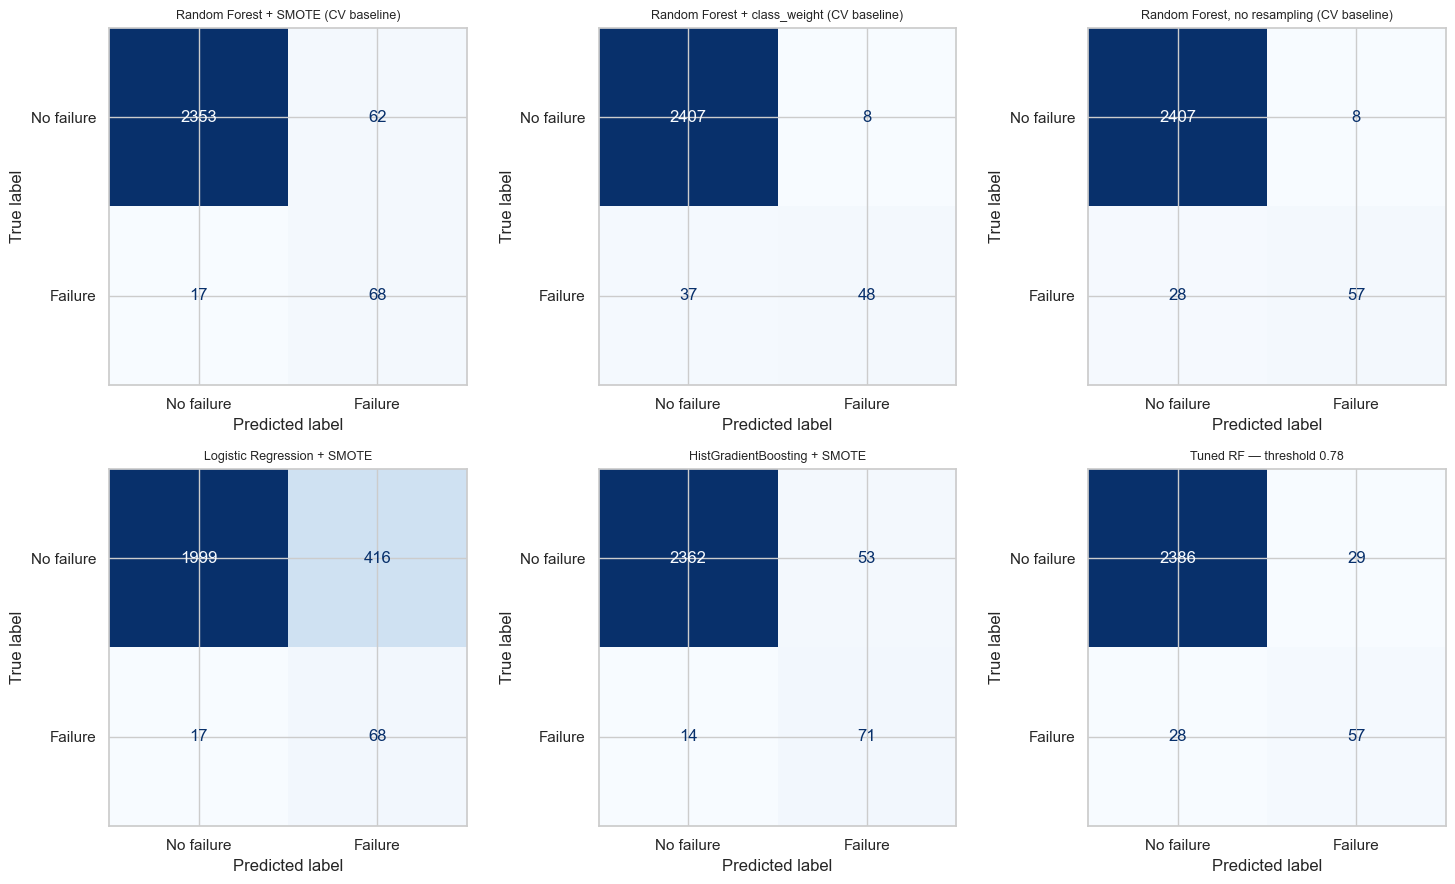

In [36]:
phase2_candidate_names = list(final_models.keys()) + [
    f'Tuned RF — threshold {selected_threshold:.2f}'
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, model_name in zip(axes.flat, phase2_candidate_names):
    preds, probs = phase2_holdout_predictions[model_name]
    print(f'\n{model_name}')
    print(classification_report(
        y_test, preds, labels=[0, 1],
        target_names=['No failure', 'Failure'], zero_division=0
    ))
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, preds, labels=[0, 1]),
        display_labels=['No failure', 'Failure']
    ).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(model_name, fontsize=9)
for ax in axes.flat[len(phase2_candidate_names):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

Tuned Random Forest — selected threshold: 0.78
              precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      2415
     Failure       0.66      0.67      0.67        85

    accuracy                           0.98      2500
   macro avg       0.83      0.83      0.83      2500
weighted avg       0.98      0.98      0.98      2500



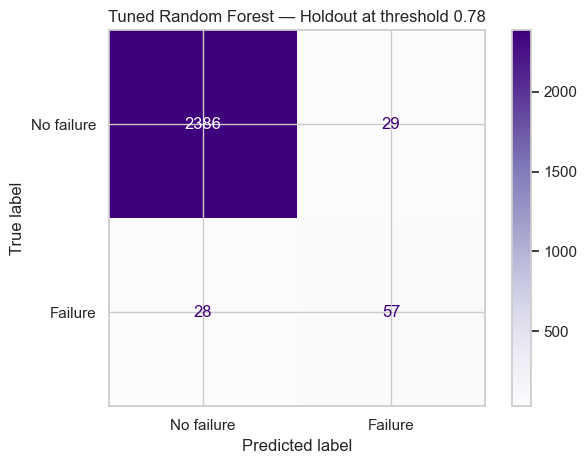

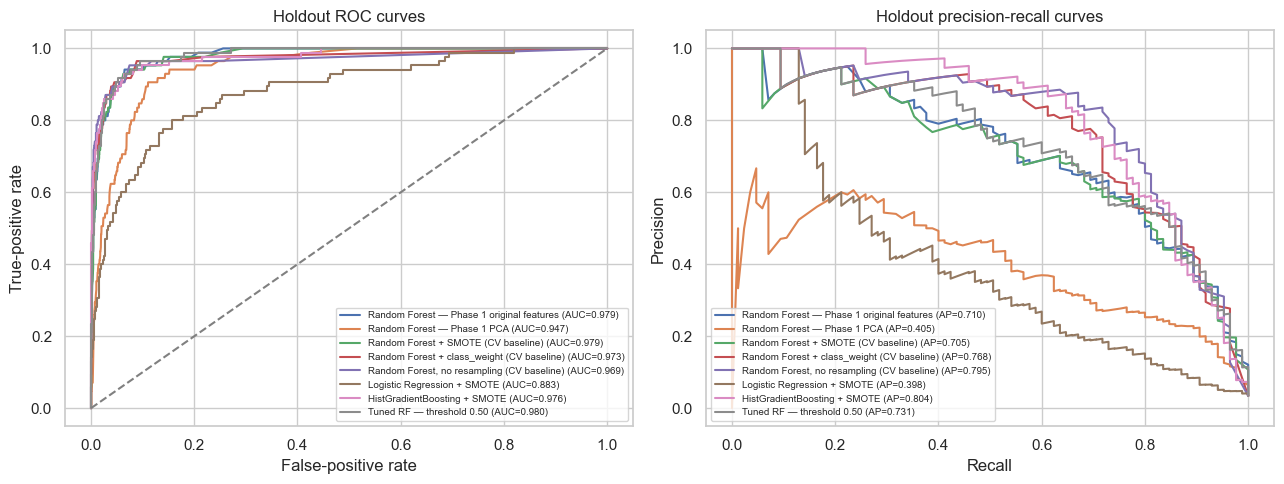

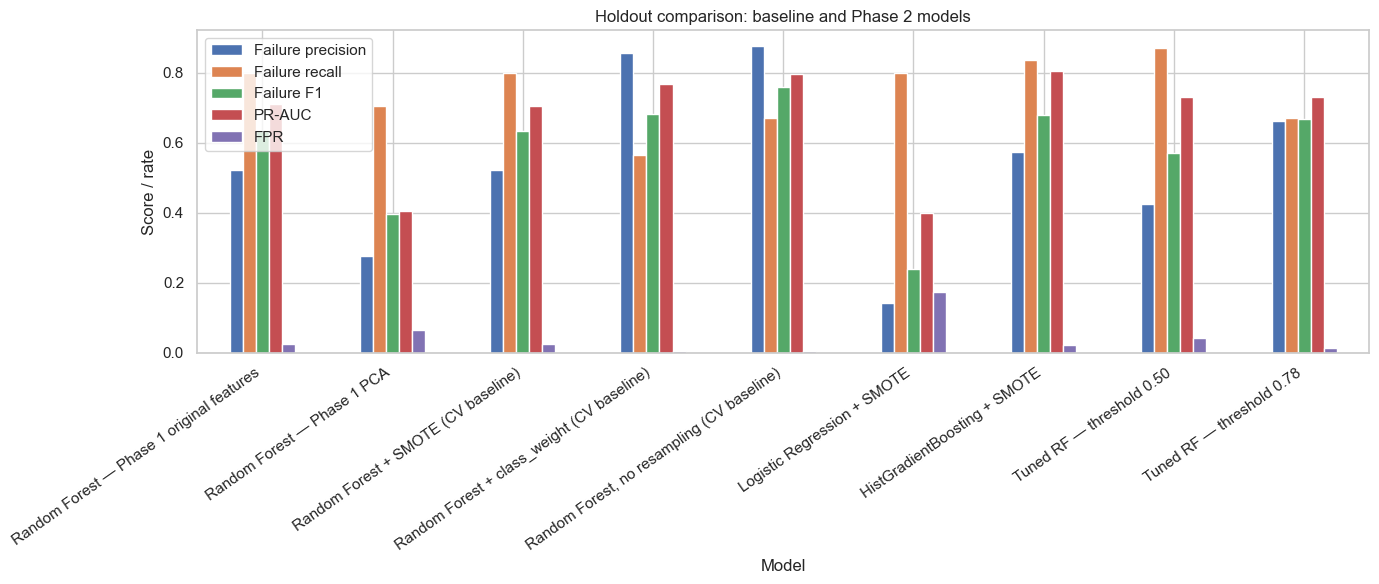

In [37]:
print('Tuned Random Forest — selected threshold:', selected_threshold)
print(classification_report(
    y_test, tuned_rf_pred_selected, labels=[0, 1],
    target_names=['No failure', 'Failure'], zero_division=0
))
selected_cm = confusion_matrix(y_test, tuned_rf_pred_selected, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=selected_cm, display_labels=['No failure', 'Failure']
).plot(cmap='Purples', values_format='d')
plt.title(f'Tuned Random Forest — Holdout at threshold {selected_threshold:.2f}')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, (preds, probs) in phase2_holdout_predictions.items():
    if model_name == f'Tuned RF — threshold {selected_threshold:.2f}':
        continue
    fpr_vals, tpr_vals, _ = roc_curve(y_test, probs)
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, probs)
    axes[0].plot(fpr_vals, tpr_vals, label=f'{model_name} (AUC={auc(fpr_vals,tpr_vals):.3f})')
    axes[1].plot(recall_vals, precision_vals, label=f'{model_name} (AP={average_precision_score(y_test,probs):.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[0].set(title='Holdout ROC curves', xlabel='False-positive rate', ylabel='True-positive rate')
axes[1].set(title='Holdout precision-recall curves', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend(fontsize=7, loc='best')
plt.tight_layout()
plt.show()

plot_metrics = ['Failure precision', 'Failure recall', 'Failure F1', 'PR-AUC', 'FPR']
phase2_holdout_summary[plot_metrics].plot(kind='bar', figsize=(14, 6))
plt.title('Holdout comparison: baseline and Phase 2 models')
plt.ylabel('Score / rate')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

### 15.7 Isolation Forest and combined alert analysis

Isolation Forest remains a standalone novelty detector fitted only to normal training rows, as in Phase 1. Its continuous anomaly score is the negated decision function: larger values mean more anomalous. The combined alert below uses the selected-threshold tuned RF OR the existing Isolation Forest alert. Results are evaluated as a policy comparison; the combined rule is not presumed superior.

,Accuracy,Failure precision,Failure recall,Failure F1,FPR,FNR,TN,FP,FN,TP,ROC-AUC,PR-AUC
Random Forest — Phase 1 original,0.9684,0.5231,0.8000,0.6326,0.0257,0.2000,2353.0,62.0,17.0,68.0,0.9795,0.7103
Isolation Forest — standalone,0.7692,0.1120,0.8353,0.1975,0.2331,0.1647,1852.0,563.0,14.0,71.0,0.8526,0.1486
Tuned RF threshold 0.78 + Isolation Forest,0.7688,0.1202,0.9176,0.2125,0.2364,0.0824,1844.0,571.0,7.0,78.0,NaN,NaN


Isolation Forest classification report (anomaly as failure proxy):
                 precision    recall  f1-score   support

     No failure       0.99      0.77      0.87      2415
Failure (proxy)       0.11      0.84      0.20        85

       accuracy                           0.77      2500
      macro avg       0.55      0.80      0.53      2500
   weighted avg       0.96      0.77      0.84      2500

Combined tuned-RF OR Isolation-Forest alert classification report:
              precision    recall  f1-score   support

  No failure       1.00      0.76      0.86      2415
     Failure       0.12      0.92      0.21        85

    accuracy                           0.77      2500
   macro avg       0.56      0.84      0.54      2500
weighted avg       0.97      0.77      0.84      2500



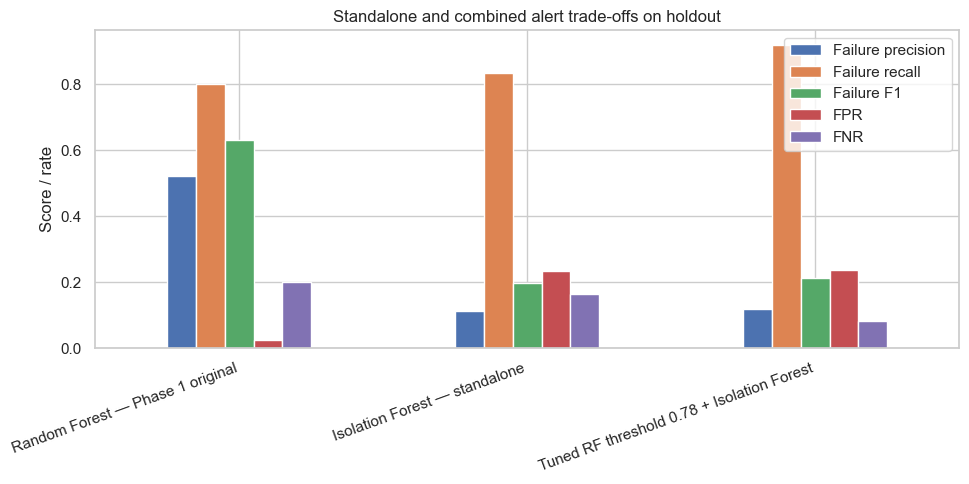

In [38]:
iso_anomaly_score = -iso_forest.decision_function(X_test_scaled_for_iso)
iso_metrics = holdout_metrics(
    y_test, y_pred_anomaly, probability=iso_anomaly_score
)
combined_tuned_alert = ((tuned_rf_pred_selected == 1) | (y_pred_anomaly == 1)).astype(int)
combined_tuned_metrics = holdout_metrics(y_test, combined_tuned_alert)

alert_comparison = pd.DataFrame({
    'Random Forest — Phase 1 original': holdout_metrics(y_test, y_pred_original, y_prob_original),
    'Isolation Forest — standalone': iso_metrics,
    f'Tuned RF threshold {selected_threshold:.2f} + Isolation Forest': combined_tuned_metrics
}).T
display(alert_comparison.round(4))

print('Isolation Forest classification report (anomaly as failure proxy):')
print(classification_report(
    y_test, y_pred_anomaly, labels=[0, 1],
    target_names=['No failure', 'Failure (proxy)'], zero_division=0
))
print('Combined tuned-RF OR Isolation-Forest alert classification report:')
print(classification_report(
    y_test, combined_tuned_alert, labels=[0, 1],
    target_names=['No failure', 'Failure'], zero_division=0
))

alert_comparison[['Failure precision', 'Failure recall', 'Failure F1', 'FPR', 'FNR']].plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Standalone and combined alert trade-offs on holdout')
plt.ylabel('Score / rate')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 15.8 Model selection summary and limitations

Use cross-validation average precision and its fold-to-fold standard deviation as the primary model-ranking evidence; inspect recall, precision, F1, and FPR/FNR alongside it. Final holdout metrics are an independent confirmation and must not be used to revisit the selected hyperparameters or threshold. Threshold choice is a policy decision: increasing recall can prevent more missed failures while raising the number of unnecessary maintenance alerts.

The training and holdout rows come from a synthetic dataset and a random row split. These metrics do not prove generalization to future production time periods, different machines, or a real factory. Validate the chosen alert policy with domain-specific maintenance costs and operational data before deployment.

## Phase 2 recommendation from this run

Under a stated operating policy that prioritizes failure recall while keeping mean five-fold FPR below 5%, **HistGradientBoosting + SMOTE** is the recommended candidate for a higher-detection demonstration: its training CV recall was 0.783 (SD 0.080), mean FPR 0.0235 (SD 0.0046), F1 0.6388 (SD 0.0548), and PR-AUC 0.7713 (SD 0.0694). On the untouched holdout it reached recall 0.8353, precision 0.5726, F1 0.6794, PR-AUC 0.8039, and FPR 0.0219. This improves recall, F1, PR-AUC, and FPR over the Phase 1 original-feature baseline for this split.

The no-resampling Random Forest remains a strong lower-alarm alternative: holdout precision 0.8769, F1 0.7600, and FPR 0.0033, but recall was 0.6706. Choose it when minimizing false alarms and maintaining precision outweighs the additional missed failures. The tuned RF at threshold 0.78 trades recall down to 0.6706 for precision 0.6628 and FPR 0.0120. The combined Isolation Forest policy raises recall to 0.9176 but lowers precision to 0.1202 and raises FPR to 0.2364, so it is not recommended as the default alert rule.

These are one split on a synthetic dataset, not a production guarantee. Validate the operating policy against real maintenance costs and time/group-based data before deployment.

# Phase 3 — Advanced anomaly detection and machine condition intelligence

Phase 1 and Phase 2 cells, outputs, and metrics above are retained. This phase distinguishes **statistical anomaly detection** from **failure classification**. The AI4I `Machine failure` label is used only as an evaluation proxy for anomaly detection and for training-only operating-point calibration; it is never passed as an Isolation Forest feature or used to fit its trees.

The original final holdout stays excluded from contamination and threshold selection. Phase 3 splits the existing training partition into a detector-development subset and a separate calibration subset. The Isolation Forest is fitted only on normal rows from detector development. Its contamination setting and optional score threshold are selected on calibration data. Final holdout metrics are computed after those choices are fixed.

In [39]:
from sklearn.inspection import permutation_importance

PHASE3_CV_SEED = RANDOM_STATE
phase3_fit_X, phase3_cal_X, phase3_fit_y, phase3_cal_y = train_test_split(
    X_train, y_train, test_size=0.25, random_state=PHASE3_CV_SEED, stratify=y_train
)
phase3_normal_fit_X = phase3_fit_X.loc[phase3_fit_y == 0]
phase3_iso_scaler = StandardScaler().fit(phase3_normal_fit_X)
phase3_normal_fit_scaled = phase3_iso_scaler.transform(phase3_normal_fit_X)
phase3_cal_scaled = phase3_iso_scaler.transform(phase3_cal_X)
phase3_test_scaled = phase3_iso_scaler.transform(X_test)

print('IF fit normal rows:', len(phase3_normal_fit_X))
print('Training-only calibration rows:', len(phase3_cal_X),
      '| calibration failures:', int(phase3_cal_y.sum()))
print('Final holdout rows (reserved):', len(X_test))

IF fit normal rows: 5434
Training-only calibration rows: 1875 | calibration failures: 63
Final holdout rows (reserved): 2500


## 3.1 Isolation Forest contamination sweep

`contamination` controls the Isolation Forest's built-in score cutoff; it does not teach the detector what a failure looks like. For each candidate value, the detector is fitted only on normal development rows. We compare its default binary outlier decisions on the separate calibration slice against recorded machine failures as a **proxy target**. The configuration is selected by highest proxy F1 among candidates with calibration FPR ≤ 5%; this is threshold calibration, not proof that every flagged point is a fault. PR-AUC uses the continuous anomaly score and the same proxy labels.

In [40]:
contamination_candidates = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10]
phase3_if_models = {}
contamination_rows = []

def phase3_binary_metrics(y_true, y_pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {
        'Precision (failure proxy)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (failure proxy)': recall_score(y_true, y_pred, zero_division=0),
        'F1 (failure proxy)': f1_score(y_true, y_pred, zero_division=0),
        'FPR': fp / (fp + tn) if fp + tn else 0.0,
        'FNR': fn / (fn + tp) if fn + tp else 0.0,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }
    if score is not None:
        out['PR-AUC (failure proxy)'] = average_precision_score(y_true, score)
    return out

for contamination in contamination_candidates:
    detector = IsolationForest(
        n_estimators=300, contamination=contamination,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    detector.fit(phase3_normal_fit_scaled)
    cal_alert = (detector.predict(phase3_cal_scaled) == -1).astype(int)
    cal_anomaly_score = -detector.score_samples(phase3_cal_scaled)
    row = phase3_binary_metrics(phase3_cal_y, cal_alert, cal_anomaly_score)
    row['Contamination'] = contamination
    contamination_rows.append(row)
    phase3_if_models[contamination] = detector

contamination_summary = pd.DataFrame(contamination_rows).set_index('Contamination')
display(contamination_summary.round(4))
feasible_contamination = contamination_summary[contamination_summary['FPR'] <= 0.05]
if feasible_contamination.empty:
    raise RuntimeError('No contamination candidate met the 5% calibration FPR cap.')
best_contamination = float(feasible_contamination.sort_values(
    ['F1 (failure proxy)', 'Recall (failure proxy)', 'Precision (failure proxy)'],
    ascending=False
).index[0])
phase3_if_selected = phase3_if_models[best_contamination]
print('Selected contamination:', best_contamination)
print('Selection rule: highest calibration failure-proxy F1 with FPR <= 5%.')
print('Anomaly flags are not supervised failure predictions.')

,Precision (failure proxy),Recall (failure proxy),F1 (failure proxy),FPR,FNR,TN,FP,FN,TP,PR-AUC (failure proxy)
Contamination,,,,,,,,,,
0.005,0.3571,0.0794,0.1299,0.0050,0.9206,1803,9,58,5,0.1748
0.010,0.2083,0.0794,0.1149,0.0105,0.9206,1793,19,58,5,0.1748
0.020,0.1538,0.0952,0.1176,0.0182,0.9048,1779,33,57,6,0.1748
0.030,0.1579,0.1429,0.1500,0.0265,0.8571,1764,48,54,9,0.1748
0.050,0.1368,0.2063,0.1646,0.0453,0.7937,1730,82,50,13,0.1748
0.075,0.1290,0.3175,0.1835,0.0745,0.6825,1677,135,43,20,0.1748
0.100,0.1343,0.4286,0.2045,0.0960,0.5714,1638,174,36,27,0.1748


Selected contamination: 0.05
Selection rule: highest calibration failure-proxy F1 with FPR <= 5%.
Anomaly flags are not supervised failure predictions.


## 3.2 Training-only anomaly score threshold analysis

The selected detector produces a continuous score (`-score_samples`; larger means more unusual). Candidate cutoffs are defined by quantiles of scores on the normal detector-fit rows, so the candidate thresholds do not depend on holdout data. We choose the cutoff on the calibration slice using the same explicit rule: maximize failure-proxy F1 with calibration FPR ≤ 5%. This overrides the built-in contamination cutoff for the calibrated alert; both operating points are reported.

,Precision (failure proxy),Recall (failure proxy),F1 (failure proxy),FPR,FNR,TN,FP,FN,TP,PR-AUC (failure proxy),Normal-fit alert fraction
Score threshold,,,,,,,,,,,
0.538665,0.1343,0.4286,0.2045,0.0960,0.5714,1638,174,36,27,0.1748,0.1001
0.571183,0.1368,0.2063,0.1646,0.0453,0.7937,1730,82,50,13,0.1748,0.0501
0.593249,0.1579,0.1429,0.1500,0.0265,0.8571,1764,48,54,9,0.1748,0.0300
0.607042,0.1538,0.0952,0.1176,0.0182,0.9048,1779,33,57,6,0.1748,0.0201
0.624422,0.2083,0.0794,0.1149,0.0105,0.9206,1793,19,58,5,0.1748,0.0101
0.641107,0.3571,0.0794,0.1299,0.0050,0.9206,1803,9,58,5,0.1748,0.0052
0.655974,0.5000,0.0476,0.0870,0.0017,0.9524,1809,3,60,3,0.1748,0.0026
0.672130,1.0000,0.0317,0.0615,0.0000,0.9683,1812,0,61,2,0.1748,0.0011


Selected anomaly score cutoff: 0.571183
Selected calibration operating point:


,Value
Precision (failure proxy),0.1368
Recall (failure proxy),0.2063
F1 (failure proxy),0.1646
FPR,0.0453
FNR,0.7937
TN,1730.0000
FP,82.0000
FN,50.0000
TP,13.0000
PR-AUC (failure proxy),0.1748


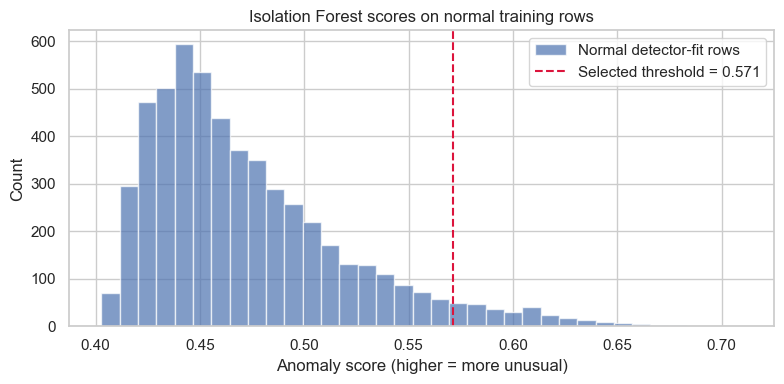

In [41]:
phase3_normal_scores = -phase3_if_selected.score_samples(phase3_normal_fit_scaled)
phase3_cal_anomaly_score = -phase3_if_selected.score_samples(phase3_cal_scaled)
quantile_candidates = [0.90, 0.95, 0.97, 0.98, 0.99, 0.995, 0.9975, 0.999]
score_threshold_candidates = sorted(set(
    [-float(phase3_if_selected.offset_)] +
    [float(np.quantile(phase3_normal_scores, q)) for q in quantile_candidates]
))
threshold_rows = []
for threshold in score_threshold_candidates:
    cal_alert = (phase3_cal_anomaly_score >= threshold).astype(int)
    row = phase3_binary_metrics(phase3_cal_y, cal_alert, phase3_cal_anomaly_score)
    row['Score threshold'] = threshold
    row['Normal-fit alert fraction'] = float(np.mean(phase3_normal_scores >= threshold))
    threshold_rows.append(row)
phase3_threshold_summary = pd.DataFrame(threshold_rows).set_index('Score threshold').sort_index()
display(phase3_threshold_summary.round(4))
feasible_score_thresholds = phase3_threshold_summary[phase3_threshold_summary['FPR'] <= 0.05]
if feasible_score_thresholds.empty:
    raise RuntimeError('No score threshold met the 5% calibration FPR cap.')
selected_if_score_threshold = float(feasible_score_thresholds.sort_values(
    ['F1 (failure proxy)', 'Recall (failure proxy)', 'Precision (failure proxy)'],
    ascending=False
).index[0])
print('Selected anomaly score cutoff:', round(selected_if_score_threshold, 6))
print('Selected calibration operating point:')
display(phase3_threshold_summary.loc[selected_if_score_threshold].to_frame('Value').round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(phase3_normal_scores, bins=35, alpha=0.7, label='Normal detector-fit rows')
ax.axvline(selected_if_score_threshold, color='crimson', linestyle='--',
           label=f'Selected threshold = {selected_if_score_threshold:.3f}')
ax.set(title='Isolation Forest scores on normal training rows', xlabel='Anomaly score (higher = more unusual)', ylabel='Count')
ax.legend()
plt.tight_layout()
plt.show()

## 3.3 Final holdout: anomaly and combined-alert comparison

The contamination and score cutoff are now frozen. The tuned Random Forest's Phase 1 model and the Phase 2 HistGradientBoosting candidate provide supervised scores. Isolation Forest provides an anomaly score. Binary OR rules combine alerts without claiming that anomalies equal failures. PR-AUC is reported for continuous supervised/anomaly scores. It is left undefined for hard OR alerts because those rules do not provide a calibrated ranking score.

,Precision (failure proxy),Recall (failure proxy),F1 (failure proxy),FPR,FNR,TN,FP,FN,TP,PR-AUC (failure proxy)
Alert policy,,,,,,,,,,
Random Forest only,0.5191,0.8000,0.6296,0.0261,0.2000,2352,63,17,68,0.7103
HistGradientBoosting only,0.5726,0.8353,0.6794,0.0219,0.1647,2362,53,14,71,0.8039
Isolation Forest — contamination default,0.1288,0.2000,0.1567,0.0476,0.8000,2300,115,68,17,0.1385
Isolation Forest — calibrated score cutoff,0.1288,0.2000,0.1567,0.0476,0.8000,2300,115,68,17,0.1385
Random Forest OR Isolation Forest,0.2979,0.8235,0.4375,0.0683,0.1765,2250,165,15,70,NaN
HistGradientBoosting OR Isolation Forest,0.3133,0.8588,0.4591,0.0663,0.1412,2255,160,12,73,NaN


Final holdout classification reports (failure label):

Random Forest only
              precision    recall  f1-score   support

  No failure       0.99      0.97      0.98      2415
     Failure       0.52      0.80      0.63        85

    accuracy                           0.97      2500
   macro avg       0.76      0.89      0.81      2500
weighted avg       0.98      0.97      0.97      2500


HistGradientBoosting only
              precision    recall  f1-score   support

  No failure       0.99      0.98      0.99      2415
     Failure       0.57      0.84      0.68        85

    accuracy                           0.97      2500
   macro avg       0.78      0.91      0.83      2500
weighted avg       0.98      0.97      0.98      2500


Isolation Forest — calibrated score cutoff
              precision    recall  f1-score   support

  No failure       0.97      0.95      0.96      2415
     Failure       0.13      0.20      0.16        85

    accuracy                         

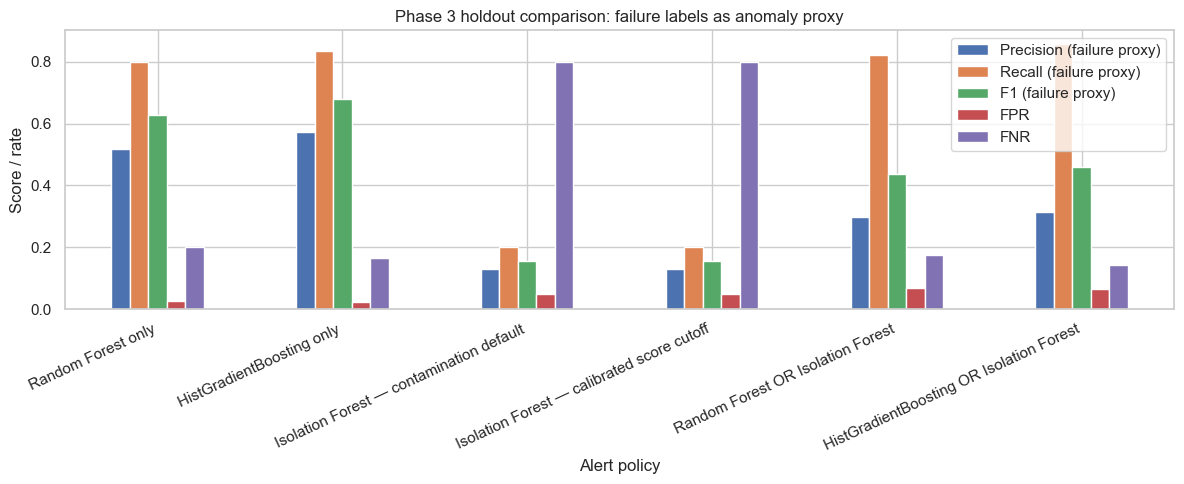

In [42]:
phase3_test_anomaly_score = -phase3_if_selected.score_samples(phase3_test_scaled)
phase3_if_default_alert = (phase3_if_selected.predict(phase3_test_scaled) == -1).astype(int)
phase3_if_calibrated_alert = (phase3_test_anomaly_score >= selected_if_score_threshold).astype(int)
phase3_rf_probability = rf_original.predict_proba(X_test_scaled)[:, 1]
phase3_rf_alert = (phase3_rf_probability >= 0.5).astype(int)
phase3_hgb = final_models['HistGradientBoosting + SMOTE']
phase3_hgb_probability = phase3_hgb.predict_proba(X_test)[:, 1]
phase3_hgb_alert = (phase3_hgb_probability >= 0.5).astype(int)
phase3_rf_or_if = ((phase3_rf_alert == 1) | (phase3_if_calibrated_alert == 1)).astype(int)
phase3_hgb_or_if = ((phase3_hgb_alert == 1) | (phase3_if_calibrated_alert == 1)).astype(int)

phase3_alert_predictions = {
    'Random Forest only': (phase3_rf_alert, phase3_rf_probability),
    'HistGradientBoosting only': (phase3_hgb_alert, phase3_hgb_probability),
    'Isolation Forest — contamination default': (phase3_if_default_alert, phase3_test_anomaly_score),
    'Isolation Forest — calibrated score cutoff': (phase3_if_calibrated_alert, phase3_test_anomaly_score),
    'Random Forest OR Isolation Forest': (phase3_rf_or_if, None),
    'HistGradientBoosting OR Isolation Forest': (phase3_hgb_or_if, None),
}
phase3_alert_rows=[]
for name,(pred,score) in phase3_alert_predictions.items():
    row=phase3_binary_metrics(y_test,pred,score)
    row['Alert policy']=name
    phase3_alert_rows.append(row)
phase3_alert_comparison=pd.DataFrame(phase3_alert_rows).set_index('Alert policy')
display(phase3_alert_comparison.round(4))

print('Final holdout classification reports (failure label):')
for name in ['Random Forest only','HistGradientBoosting only',
             'Isolation Forest — calibrated score cutoff',
             'Random Forest OR Isolation Forest',
             'HistGradientBoosting OR Isolation Forest']:
    pred,_=phase3_alert_predictions[name]
    print('\n'+name)
    print(classification_report(y_test,pred,labels=[0,1],
          target_names=['No failure','Failure'],zero_division=0))

fig,ax=plt.subplots(figsize=(12,5))
phase3_alert_comparison[['Precision (failure proxy)','Recall (failure proxy)',
                          'F1 (failure proxy)','FPR','FNR']].plot(kind='bar',ax=ax)
ax.set_title('Phase 3 holdout comparison: failure labels as anomaly proxy')
ax.set_ylabel('Score / rate')
plt.xticks(rotation=25,ha='right')
plt.tight_layout()
plt.show()

## 3.4 False-positive investigation

Here, an Isolation Forest false positive means a test observation flagged as anomalous while `Machine failure` is 0. This is a disagreement with the recorded failure label, not evidence that the detector or label is necessarily wrong. We compare these observations with normal, non-anomalous test rows by sensor summaries and product type to identify possible operating-regime patterns for review.

Non-failure rows flagged anomalous: 115 of 2415
Share of normal test rows flagged: 0.0476


,Flagged non-failure median,Unflagged non-failure median,Flagged non-failure mean,Unflagged non-failure mean,Mean difference / training normal SD
Air temperature [K],299.4,300.0,299.504,299.990,-0.242
Process temperature [K],309.5,310.1,309.426,310.026,-0.402
Rotational speed [rpm],1802.0,1503.5,1781.887,1525.848,1.529
Torque [Nm],26.0,40.0,31.770,40.097,-0.879
Tool wear [min],111.0,109.0,106.191,107.743,-0.025


Product type mix among non-failure rows:


IF calibrated alert,Unflagged normal,Flagged non-failure
Type,,
H,10.17,11.30
L,59.17,54.78
M,30.65,33.91


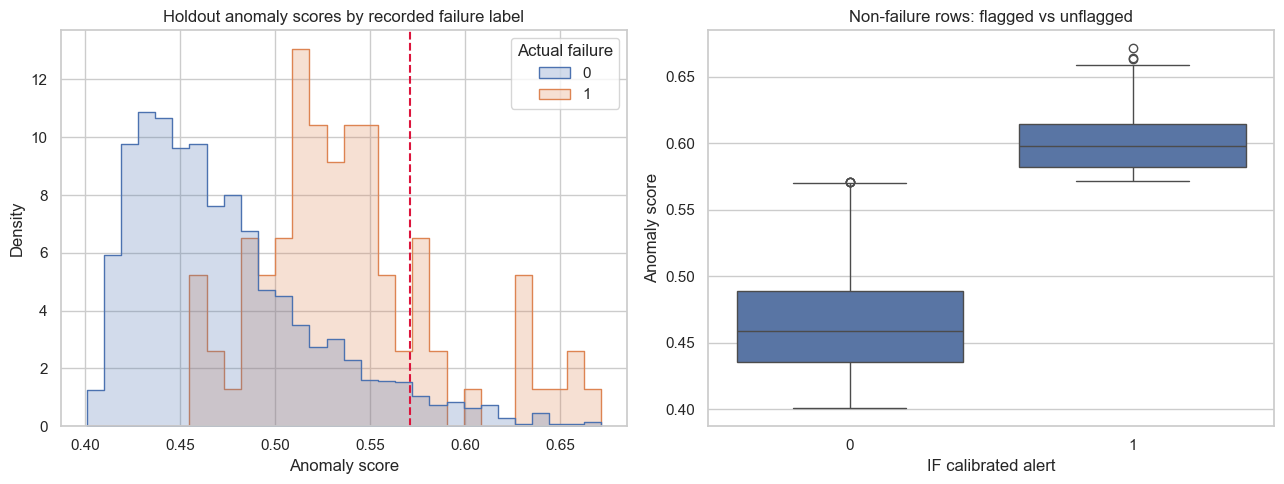

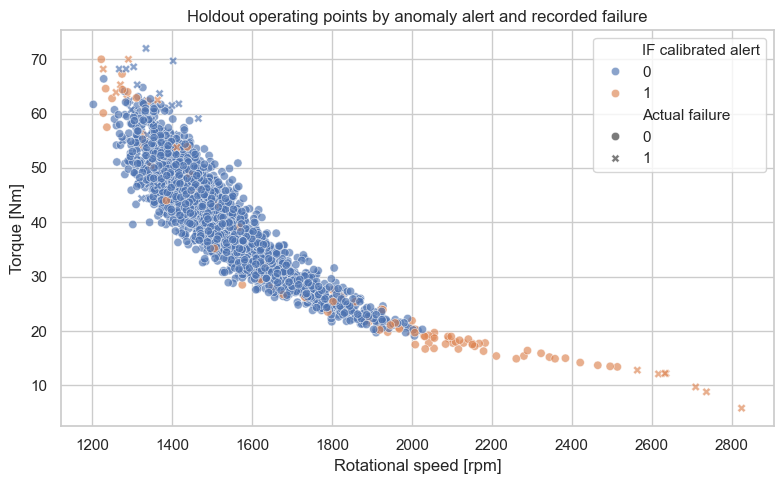

In [43]:
phase3_test_frame = df.loc[X_test.index].copy()
phase3_test_frame['Actual failure'] = y_test
phase3_test_frame['Anomaly score'] = phase3_test_anomaly_score
phase3_test_frame['IF calibrated alert'] = phase3_if_calibrated_alert
phase3_test_frame['HGB failure prediction'] = phase3_hgb_alert
phase3_fp_mask = (phase3_test_frame['Actual failure']==0) & (phase3_test_frame['IF calibrated alert']==1)
phase3_tn_mask = (phase3_test_frame['Actual failure']==0) & (phase3_test_frame['IF calibrated alert']==0)
phase3_false_positives = phase3_test_frame.loc[phase3_fp_mask]
phase3_normal_unflagged = phase3_test_frame.loc[phase3_tn_mask]
print('Non-failure rows flagged anomalous:',len(phase3_false_positives),
      'of',int((y_test==0).sum()))
print('Share of normal test rows flagged:',round(len(phase3_false_positives)/max(1,int((y_test==0).sum())),4))

fp_sensor_summary=pd.DataFrame({
    'Flagged non-failure median':phase3_false_positives[sensor_features].median(),
    'Unflagged non-failure median':phase3_normal_unflagged[sensor_features].median(),
    'Flagged non-failure mean':phase3_false_positives[sensor_features].mean(),
    'Unflagged non-failure mean':phase3_normal_unflagged[sensor_features].mean(),
})
fp_sensor_summary['Mean difference / training normal SD']=(
    fp_sensor_summary['Flagged non-failure mean']-fp_sensor_summary['Unflagged non-failure mean']
)/phase3_normal_fit_X.std().replace(0,np.nan)
display(fp_sensor_summary.round(3))
if 'Type' in phase3_test_frame.columns:
    print('Product type mix among non-failure rows:')
    type_mix=pd.crosstab(phase3_test_frame.loc[phase3_test_frame['Actual failure']==0,'Type'],
        phase3_test_frame.loc[phase3_test_frame['Actual failure']==0,'IF calibrated alert'],
        normalize='columns').rename(columns={0:'Unflagged normal',1:'Flagged non-failure'})
    display((100*type_mix).round(2))

fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.histplot(data=phase3_test_frame,x='Anomaly score',hue='Actual failure',
             stat='density',common_norm=False,element='step',ax=axes[0])
axes[0].axvline(selected_if_score_threshold,color='crimson',linestyle='--')
axes[0].set_title('Holdout anomaly scores by recorded failure label')
sns.boxplot(data=phase3_test_frame[phase3_test_frame['Actual failure']==0],
            x='IF calibrated alert',y='Anomaly score',ax=axes[1])
axes[1].set_title('Non-failure rows: flagged vs unflagged')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(data=phase3_test_frame,x='Rotational speed [rpm]',y='Torque [Nm]',
                hue='IF calibrated alert',style='Actual failure',alpha=.65)
plt.title('Holdout operating points by anomaly alert and recorded failure')
plt.tight_layout()
plt.show()

## 3.5 Machine condition intelligence: three explainable states

Use the Phase 2 HistGradientBoosting model at its documented 0.5 threshold as the primary supervised risk signal. If it predicts failure, return **FAILURE RISK**. If it does not, but the calibrated Isolation Forest score exceeds its training-selected cutoff, return **ANOMALOUS CONDITION**. Otherwise return **NORMAL CONDITION**. The anomalous state is an inspection prompt, not a failure diagnosis. No probability fusion is used: the anomaly score is not calibrated as a failure probability, and a fusion model would need a separate, representative calibration design.

,Actual failure,HGB failure probability,HGB failure prediction,IF anomaly score,IF anomaly alert,Machine condition
1390,0,0.004858,0,0.461464,0,NORMAL CONDITION
2925,0,0.003458,0,0.444842,0,NORMAL CONDITION
2488,0,0.003031,0,0.470730,0,NORMAL CONDITION
5844,0,0.000433,0,0.437197,0,NORMAL CONDITION
7978,0,0.002132,0,0.491943,0,NORMAL CONDITION
4161,0,0.003185,0,0.441779,0,NORMAL CONDITION
3132,0,0.001345,0,0.423838,0,NORMAL CONDITION
1092,0,0.000220,0,0.544436,0,NORMAL CONDITION
67,0,0.018231,0,0.438870,0,NORMAL CONDITION
5,0,0.000284,0,0.460700,0,NORMAL CONDITION


,Observations
Machine condition,
NORMAL CONDITION,2267
FAILURE RISK,124
ANOMALOUS CONDITION,109


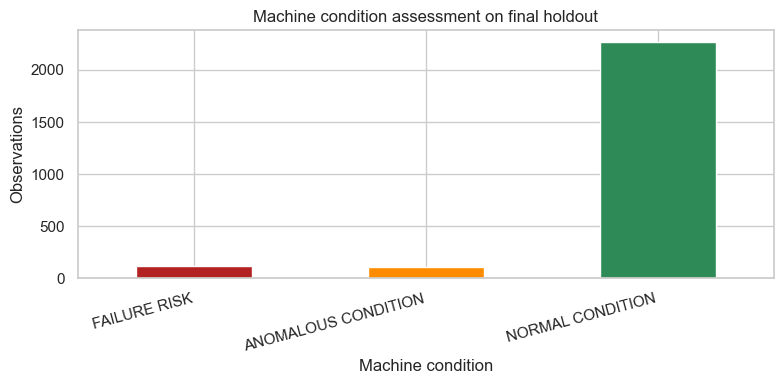

In [44]:
phase3_condition = np.select(
    [phase3_hgb_alert==1, (phase3_hgb_alert==0)&(phase3_if_calibrated_alert==1)],
    ['FAILURE RISK','ANOMALOUS CONDITION'], default='NORMAL CONDITION'
)
phase3_condition_assessment=pd.DataFrame({
    'Actual failure':y_test.to_numpy(),
    'HGB failure probability':phase3_hgb_probability,
    'HGB failure prediction':phase3_hgb_alert,
    'IF anomaly score':phase3_test_anomaly_score,
    'IF anomaly alert':phase3_if_calibrated_alert,
    'Machine condition':phase3_condition
},index=y_test.index)
display(phase3_condition_assessment.head(12))
condition_counts=phase3_condition_assessment['Machine condition'].value_counts()
display(condition_counts.rename('Observations').to_frame())
fig,ax=plt.subplots(figsize=(8,4))
condition_counts.reindex(['FAILURE RISK','ANOMALOUS CONDITION','NORMAL CONDITION'],fill_value=0).plot(
    kind='bar',color=['firebrick','darkorange','seagreen'],ax=ax
)
ax.set_title('Machine condition assessment on final holdout')
ax.set_ylabel('Observations')
plt.xticks(rotation=15,ha='right')
plt.tight_layout()
plt.show()

## 3.6 Sensor-level and individual-case explanations

Random Forest impurity importance is retained as a global model summary. HistGradientBoosting has no built-in impurity importances here, so permutation importance is computed once on the final holdout after models and thresholds are frozen; it is descriptive and is not fed back into training or model selection. Neither importance measure establishes causality. SHAP is not installed in the current environment, so this phase avoids adding another dependency. Individual cases are described with model outputs and deviations from normal training sensor distributions; these contextual summaries explain what to inspect, not why a machine failed.

,RF impurity importance,HGB permutation importance (AP decrease)
Torque [Nm],0.3430,0.6499
Air temperature [K],0.0918,0.4447
Rotational speed [rpm],0.2912,0.3667
Tool wear [min],0.2126,0.3300
Process temperature [K],0.0614,0.2095


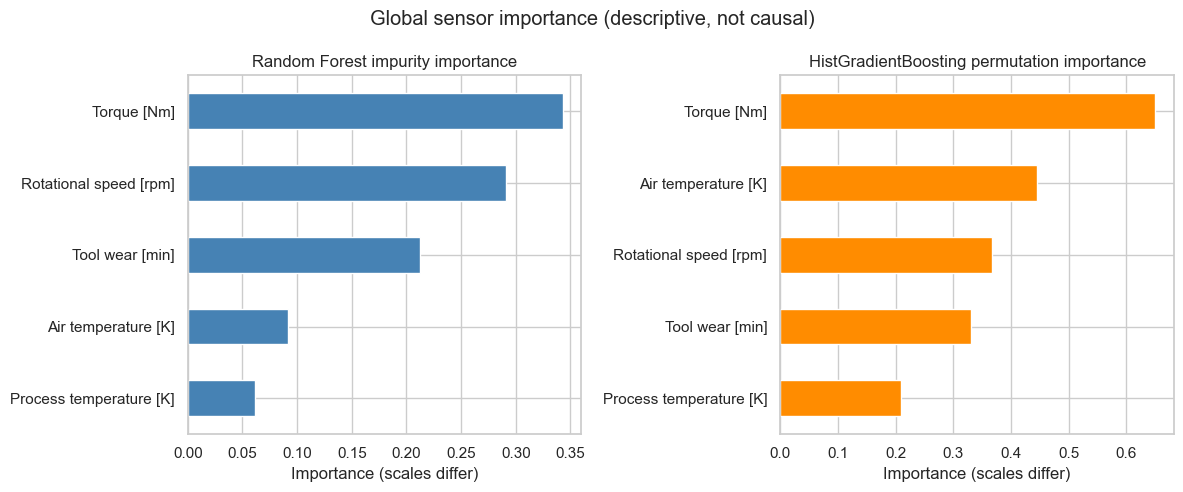

,Row index,HGB failure probability,IF anomaly score,Recorded failure (evaluation only),Most unusual sensor values vs training mean
Condition,,,,,
FAILURE RISK,8307,0.999786,0.529839,1,Torque [Nm]=69.70 (|z|=2.97); Rotational speed...
ANOMALOUS CONDITION,852,0.000098,0.576554,0,Air temperature [K]=296.30 (|z|=1.85); Process...
NORMAL CONDITION,1390,0.004858,0.461464,0,Torque [Nm]=54.80 (|z|=1.48); Rotational speed...


In [45]:
rf_importance_phase3=pd.Series(rf_original.feature_importances_,index=sensor_features,name='RF impurity importance')
hgb_permutation=permutation_importance(
    phase3_hgb,X_test,y_test,n_repeats=5,random_state=RANDOM_STATE,
    scoring='average_precision',n_jobs=1
)
hgb_importance_phase3=pd.Series(
    hgb_permutation.importances_mean,index=sensor_features,name='HGB permutation importance (AP decrease)'
)
importance_table=pd.concat([rf_importance_phase3,hgb_importance_phase3],axis=1).sort_values(
    'HGB permutation importance (AP decrease)',ascending=False
)
display(importance_table.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,5))
rf_importance_phase3.sort_values().plot(kind='barh',ax=axes[0],color='steelblue')
axes[0].set_title('Random Forest impurity importance')
hgb_importance_phase3.sort_values().plot(kind='barh',ax=axes[1],color='darkorange')
axes[1].set_title('HistGradientBoosting permutation importance')
for ax in axes: ax.set_xlabel('Importance (scales differ)')
plt.suptitle('Global sensor importance (descriptive, not causal)')
plt.tight_layout()
plt.show()

case_rows=[]
train_sensor_mean=X_train.mean()
train_sensor_std=X_train.std().replace(0,np.nan)
for state in ['FAILURE RISK','ANOMALOUS CONDITION','NORMAL CONDITION']:
    candidates=phase3_condition_assessment.index[phase3_condition_assessment['Machine condition']==state]
    if len(candidates)==0: continue
    idx=candidates[0]
    vals=X_test.loc[idx]
    z=((vals-train_sensor_mean)/train_sensor_std).abs().sort_values(ascending=False)
    record={
        'Row index':idx,'Condition':state,
        'HGB failure probability':phase3_condition_assessment.loc[idx,'HGB failure probability'],
        'IF anomaly score':phase3_condition_assessment.loc[idx,'IF anomaly score'],
        'Recorded failure (evaluation only)':int(y_test.loc[idx]),
        'Most unusual sensor values vs training mean':'; '.join(
            f'{feature}={vals[feature]:.2f} (|z|={z[feature]:.2f})' for feature in z.index[:2]
        )
    }
    case_rows.append(record)
display(pd.DataFrame(case_rows).set_index('Condition'))

## 3.7 Phase 3 interpretation and limits

Compare recall with precision and FPR before adopting an alert rule. OR logic will generally broaden alert coverage but can create many false alarms; it is only useful if the maintenance workflow can absorb them. An Isolation Forest false positive may reflect a rare but valid sensor regime, a synthetic-label mismatch, or a true unusual condition not represented by the binary failure target. Review sensor context and operational records before assigning a fault.

The calibrated contamination/score cutoff is tied to this dataset split and its label-based proxy calibration. The condition states are classification and anomaly triage only. This project does not estimate remaining useful life, confirm a physical fault, or establish production safety.